# Graphic Functions

#### Imports for Plots

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re

#### Boxplot Function

In [2]:

def plot_boxplot(
    df,
    title="Boxplot per sample (zeros ignored)",
    rename_dict=None,
    block_size=12,
    gray_count=5,
    title_size=14,
    xtick_labelsize=12,
    ytick_labelsize=12,
    xlabel=None,
    ylabel=None,
    xlabel_size=12,
    ylabel_size=12
):
    """
    Plot a boxplot for each sample, ignoring zero values.

    Parameters
    ----------
    df : pandas.DataFrame
        Input abundance matrix, with samples represented by columns.
    title : str, optional
        Title displayed above the plot.
    rename_dict : dict, optional
        Dictionary used to rename sample columns for visualization.
    block_size : int, optional
        Number of consecutive samples assigned to each color block.
    gray_count : int, optional
        Number of final samples displayed in gray.
    title_size : int, optional
        Font size of the plot title.
    xtick_labelsize : int, optional
        Font size of the x-axis tick labels.
    ytick_labelsize : int, optional
        Font size of the y-axis tick labels.
    xlabel, ylabel : str, optional
        Labels for the x- and y-axes.
    xlabel_size, ylabel_size : int, optional
        Font sizes of the axis labels.

    Notes
    -----
    Zero values are replaced with NaN in a copy of the input DataFrame
    before plotting. The original DataFrame is not modified.

    Sample colors are assigned in consecutive blocks, with the final
    `gray_count` samples displayed in gray.
    """

    # ---------------------------------------------------------
    # 1. Prepare the data for visualization
    # ---------------------------------------------------------

    # Replace zero values with NaN so they are excluded from the boxplots.
    df_plot = df.replace(0, np.nan)

    # Optionally rename columns for display purposes.
    if rename_dict and isinstance(rename_dict, dict):
        df_plot = df_plot.rename(columns=rename_dict)

    # Get the number of samples (columns) to be plotted.
    n_cols = df_plot.shape[1]

    # ---------------------------------------------------------
    # 2. Define the color scheme
    # ---------------------------------------------------------

    # Colors assigned to consecutive blocks of samples.
    base_colors = [
        "#ADD8E6", "#1f77b4",
        "#F08080", "#d62728",
        "#90EE90", "#2ca02c"
    ]

    # Color used for the final group of samples.
    gray_color = "#d3d3d3"

    # Build the color list according to the sample order.
    colors = []
    i = 0

    while len(colors) < n_cols - gray_count:
        colors.extend([base_colors[i % len(base_colors)]] * block_size)
        i += 1

    # Match the number of colors to the non-gray samples.
    colors = colors[:n_cols - gray_count]

    # Assign gray to the final samples.
    colors.extend([gray_color] * gray_count)

    # Ensure that each sample has exactly one assigned color.
    if len(colors) != n_cols:
        raise ValueError(
            f"Color list length ({len(colors)}) does not match "
            f"number of columns ({n_cols})"
        )

    # ---------------------------------------------------------
    # 3. Create the boxplot
    # ---------------------------------------------------------

    fig, ax = plt.subplots(figsize=(14, 7), dpi=300)

    sns.boxplot(
        data=df_plot,
        showfliers=False,
        palette=colors,
        ax=ax
    )

    # ---------------------------------------------------------
    # 4. Format the plot
    # ---------------------------------------------------------

    # Set the title and tick-label font sizes.
    ax.set_title(title, fontsize=title_size)
    ax.tick_params(axis="x", labelsize=xtick_labelsize)
    ax.tick_params(axis="y", labelsize=ytick_labelsize)

    # Set axis labels when provided.
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=xlabel_size)

    if ylabel:
        ax.set_ylabel(ylabel, fontsize=ylabel_size)

    # Rotate sample labels to improve readability.
    plt.xticks(rotation=90)

    # Adjust spacing to prevent overlapping elements.
    plt.tight_layout()

    # Display the figure and release its memory afterward.
    plt.show()
    plt.close(fig)


#### Histogram Function

In [3]:

def plot_histograms(
    df,
    individual=True,
    grouped=True,
    include_zeros=False,
    rename_dict=None,
    xlim=None,
    ylim=False,
    xticksDisplayed=None,
    yticksDisplayed=None,
    xlabel=None,
    ylabel=None,
    title=None,
    title_size=12,
    xtick_labelsize=12,
    ytick_labelsize=12,
    xlabel_size=12,
    ylabel_size=12
):
    """
    Plot individual histograms for each sample and/or a grouped histogram.

    Parameters
    ----------
    df : pandas.DataFrame
        Input abundance matrix, with samples represented by columns.
    individual : bool, optional
        If True, plot individual histograms for each sample.
    grouped : bool, optional
        If True, plot a single histogram using values from all samples.
    include_zeros : bool, optional
        If False, replace zero values with NaN before plotting.
        If True, retain zero values in the plotted data.
    rename_dict : dict, optional
        Dictionary used to rename sample columns for visualization.
    xlim, ylim : tuple, optional
        Axis limits for the x- and y-axes, respectively.
    xticksDisplayed, yticksDisplayed : list, optional
        Custom tick positions for the x- and y-axes.
    xlabel, ylabel : str, optional
        Labels for the x- and y-axes.
    title : str, optional
        Custom title for the grouped histogram.
    title_size : int, optional
        Font size of the plot titles.
    xtick_labelsize, ytick_labelsize : int, optional
        Font sizes of the axis tick labels.
    xlabel_size, ylabel_size : int, optional
        Font sizes of the axis labels.

    Notes
    -----
    Individual histograms are displayed in groups of three samples.
    The grouped histogram combines all non-NaN values across the
    input columns into a single distribution.
    """

    # ---------------------------------------------------------
    # 1. Prepare the data
    # ---------------------------------------------------------

    # Optionally exclude zero values by replacing them with NaN.
    if not include_zeros:
        df_plot = df.replace(0, np.nan)
    else:
        df_plot = df.copy()

    # Rename only columns present in the input DataFrame.
    if rename_dict:
        valid_rename_dict = {
            k: v for k, v in rename_dict.items()
            if k in df_plot.columns
        }
        df_plot = df_plot.rename(columns=valid_rename_dict)

    # Retrieve the column names for plotting.
    cols = df_plot.columns.tolist()

    # ---------------------------------------------------------
    # 2. Plot individual histograms
    # ---------------------------------------------------------

    if individual:
        # Display up to three samples per figure.
        group_size = 3

        for start in range(0, len(cols), group_size):
            end = min(start + group_size, len(cols))
            group_cols = cols[start:end]

            # Create one subplot for each sample in the current group.
            fig, axes = plt.subplots(
                1,
                len(group_cols),
                figsize=(len(group_cols) * 2.5, 2.5),
                dpi=300
            )

            # Ensure that axes is iterable when only one sample is plotted.
            if len(group_cols) == 1:
                axes = [axes]

            for ax, col in zip(axes, group_cols):
                # Plot the distribution of values for the current sample.
                sns.histplot(
                    df_plot[col],
                    bins=100,
                    kde=False,
                    ax=ax,
                    color="steelblue"
                )

                # Format the subplot title and tick labels.
                ax.set_title(col, fontsize=title_size)
                ax.tick_params(axis="x", labelsize=xtick_labelsize)
                ax.tick_params(axis="y", labelsize=ytick_labelsize)

                # Apply custom axis limits when provided.
                if xlim:
                    ax.set_xlim(xlim)

                if ylim:
                    ax.set_ylim(ylim)

                # Apply custom tick positions when provided.
                if xticksDisplayed:
                    ax.set_xticks(xticksDisplayed)

                if yticksDisplayed:
                    ax.set_yticks(yticksDisplayed)

                # Set axis labels; use empty strings when not specified.
                ax.set_xlabel(
                    xlabel if xlabel else "",
                    fontsize=xlabel_size
                )
                ax.set_ylabel(
                    ylabel if ylabel else "",
                    fontsize=ylabel_size
                )

            # Adjust subplot spacing, display the figure, and release memory.
            plt.tight_layout()
            plt.show()
            plt.close(fig)

    # ---------------------------------------------------------
    # 3. Plot the grouped histogram
    # ---------------------------------------------------------

    if grouped:
        fig, ax = plt.subplots(figsize=(9, 3), dpi=300)

        # Combine all sample values into a single one-dimensional array.
        # NaN values are removed before plotting.
        data = df_plot.to_numpy().ravel()
        data = data[~np.isnan(data)]

        # Plot the combined distribution.
        sns.histplot(
            data,
            bins=50,
            kde=False,
            color="steelblue",
            ax=ax
        )

        # Apply custom axis limits when provided.
        if xlim:
            ax.set_xlim(xlim)

        if ylim:
            ax.set_ylim(ylim)

        # Apply custom tick positions and formatting.
        if xticksDisplayed:
            ax.set_xticks(xticksDisplayed)
            ax.tick_params(axis="x", labelsize=xtick_labelsize)

        if yticksDisplayed:
            ax.set_yticks(yticksDisplayed)
            ax.tick_params(axis="y", labelsize=ytick_labelsize)

        # Use a default title based on whether zeros are included.
        title_to_use = title if title else (
            "Histogram (including zeros)"
            if include_zeros
            else "Histogram (zeros ignored)"
        )

        ax.set_title(title_to_use, fontsize=title_size)

        # Set axis labels, using defaults when none are provided.
        ax.set_xlabel(
            xlabel if xlabel else "Value",
            fontsize=xlabel_size
        )
        ax.set_ylabel(
            ylabel if ylabel else "Count",
            fontsize=ylabel_size
        )

        # Display the figure and release its memory.
        plt.show()
        plt.close(fig)


#### Histogram Compare

In [4]:

def plot_histograms_compare(
    df_original,
    df_imputed,
    individual=True,
    grouped=True,
    include_zeros=False,
    rename_dict=None,
    xlim=None,
    ylim=None,
    xticksDisplayed=[5, 15, 25],
    yticksDisplayed=[0, 650],
    xlabel=None,
    ylabel=None,
    title=None,
    title_size=12,
    xtick_labelsize=12,
    ytick_labelsize=12,
    xlabel_size=12,
    ylabel_size=12
):
    """
    Compare the distributions of original and imputed values using histograms.

    Parameters
    ----------
    df_original : pandas.DataFrame
        Original abundance matrix before imputation.
    df_imputed : pandas.DataFrame
        Abundance matrix after imputation.
    individual : bool, optional
        If True, plot separate histograms for each sample.
    grouped : bool, optional
        If True, plot a combined histogram across all samples.
    include_zeros : bool, optional
        If False, replace zero values with NaN before plotting.
    rename_dict : dict, optional
        Dictionary used to rename sample columns for visualization.
    xlim, ylim : tuple, optional
        Axis limits for the x- and y-axes, respectively.
    xticksDisplayed, yticksDisplayed : list, optional
        Custom tick positions for the x- and y-axes.
    xlabel, ylabel : str, optional
        Labels for the x- and y-axes.
    title : str, optional
        Custom title for the grouped histogram.
    title_size : int, optional
        Font size of the plot titles.
    xtick_labelsize, ytick_labelsize : int, optional
        Font sizes of the axis tick labels.
    xlabel_size, ylabel_size : int, optional
        Font sizes of the axis labels.

    Notes
    -----
    Values are classified as original or imputed according to missing
    positions in the original DataFrame. Original values are displayed
    in blue, while imputed values are displayed in red.
    """

    # ---------------------------------------------------------
    # 1. Prepare the data
    # ---------------------------------------------------------

    # Optionally replace zero values with NaN in both DataFrames.
    if not include_zeros:
        df_original_plot = df_original.replace(0, np.nan)
        df_imputed_plot = df_imputed.replace(0, np.nan)
    else:
        df_original_plot = df_original.copy()
        df_imputed_plot = df_imputed.copy()

    # Rename sample columns when a mapping is provided.
    if rename_dict:
        valid_rename_dict = {
            k: v for k, v in rename_dict.items()
            if k in df_imputed_plot.columns
        }
        df_original_plot = df_original_plot.rename(
            columns=valid_rename_dict
        )
        df_imputed_plot = df_imputed_plot.rename(
            columns=valid_rename_dict
        )

    # Retrieve sample names and identify missing positions
    # in the original abundance matrix.
    cols = df_imputed_plot.columns.tolist()
    mask_imputed = df_original_plot.isna()

    # ---------------------------------------------------------
    # 2. Plot individual histograms
    # ---------------------------------------------------------

    if individual:
        # Display up to three samples per figure.
        group_size = 3

        for start in range(0, len(cols), group_size):
            end = min(start + group_size, len(cols))
            group_cols = cols[start:end]

            # Create one subplot per sample in the current group.
            fig, axes = plt.subplots(
                1,
                len(group_cols),
                figsize=(len(group_cols) * 2.5, 2.5),
                dpi=300
            )

            # Ensure that axes is iterable for a single-sample figure.
            if len(group_cols) == 1:
                axes = [axes]

            for ax, col in zip(axes, group_cols):
                # Separate observed and imputed values using the
                # missing-value mask derived from the original data.
                orig_values = df_imputed_plot.loc[
                    ~mask_imputed[col], col
                ].dropna()

                imp_values = df_imputed_plot.loc[
                    mask_imputed[col], col
                ].dropna()

                # Plot observed values in blue and imputed values in red.
                sns.histplot(
                    orig_values,
                    bins=100,
                    kde=False,
                    ax=ax,
                    color="steelblue",
                    alpha=0.6,
                    label="Original"
                )

                sns.histplot(
                    imp_values,
                    bins=100,
                    kde=False,
                    ax=ax,
                    color="red",
                    alpha=0.6,
                    label="Imputed"
                )

                # Format the subplot title and tick labels.
                ax.set_title(col, fontsize=title_size)
                ax.tick_params(axis="x", labelsize=xtick_labelsize)
                ax.tick_params(axis="y", labelsize=ytick_labelsize)

                # Apply custom axis limits when provided.
                if xlim:
                    ax.set_xlim(xlim)

                if ylim:
                    ax.set_ylim(ylim)

                # Apply custom tick positions when provided.
                if xticksDisplayed:
                    ax.set_xticks(xticksDisplayed)

                if yticksDisplayed:
                    ax.set_yticks(yticksDisplayed)

                # Set axis labels; use empty strings when unspecified.
                ax.set_xlabel(
                    xlabel if xlabel else "",
                    fontsize=xlabel_size
                )
                ax.set_ylabel(
                    ylabel if ylabel else "",
                    fontsize=ylabel_size
                )

                # Display the legend in the upper-right corner.
                ax.legend(loc="upper right", fontsize=8)

            # Adjust spacing, display the figure, and release memory.
            plt.tight_layout()
            plt.show()
            plt.close(fig)

    # ---------------------------------------------------------
    # 3. Plot the grouped histogram
    # ---------------------------------------------------------

    if grouped:
        plt.figure(figsize=(9, 3), dpi=300)

        # Collect observed and imputed values across all samples.
        orig_values_all = (
            df_imputed_plot.where(~mask_imputed).to_numpy().ravel()
        )
        imp_values_all = (
            df_imputed_plot.where(mask_imputed).to_numpy().ravel()
        )

        # Remove NaN values before plotting.
        orig_values_all = orig_values_all[
            ~np.isnan(orig_values_all)
        ]
        imp_values_all = imp_values_all[
            ~np.isnan(imp_values_all)
        ]

        # Overlay the observed and imputed value distributions.
        sns.histplot(
            orig_values_all,
            bins=50,
            kde=False,
            color="steelblue",
            alpha=0.6,
            label="Original"
        )

        sns.histplot(
            imp_values_all,
            bins=50,
            kde=False,
            color="red",
            alpha=0.6,
            label="Imputed"
        )

        # Apply custom axis limits when provided.
        if xlim:
            plt.xlim(xlim)

        if ylim:
            plt.ylim(ylim)

        # Apply custom tick positions and formatting.
        if xticksDisplayed:
            plt.xticks(
                xticksDisplayed,
                fontsize=xtick_labelsize
            )

        if yticksDisplayed:
            plt.yticks(
                yticksDisplayed,
                fontsize=ytick_labelsize
            )

        # Use a default title based on whether zeros are included.
        title_to_use = title if title else (
            "Histogram (including zeros)"
            if include_zeros
            else "Histogram (zeros ignored)"
        )

        plt.title(title_to_use, fontsize=title_size)

        # Set axis labels, using defaults when unspecified.
        plt.xlabel(
            xlabel if xlabel else "Value",
            fontsize=xlabel_size
        )
        plt.ylabel(
            ylabel if ylabel else "Count",
            fontsize=ylabel_size
        )

        # Display the legend, show the figure, and release memory.
        plt.legend(loc="upper right")
        plt.show()
        plt.close()


#### Summarizing Zeros

In [5]:

def summarize_zeros(df: pd.DataFrame, bin_size: int = 10, title="", letter=""):
    """
    Summarize and visualize the percentage of zeros per row using manual bins.

    NaN values are treated as zeros for counting purposes. The bin width
    can be adjusted manually; the default bin size is 10 percentage points.

    Parameters
    ----------
    df : pandas.DataFrame
        Input DataFrame.
    bin_size : int, optional
        Width of each bin in percentage points. Defaults to 10.
    title : str, optional
        Additional text to include in the plot title.
    letter : str, optional
        Prefix to include in the plot title.

    Returns
    -------
    pandas.Series
        Number of rows in each percentage bin.
    """

    # ---------------------------------------------------------
    # 1. Prepare the data and calculate zero percentages
    # ---------------------------------------------------------

    # Replace NaN values with zero for zero counting only.
    df_for_zeros = df.fillna(0)

    # Calculate the percentage of zeros in each row.
    zero_frac_per_row = (
        (df_for_zeros == 0).sum(axis=1) / df_for_zeros.shape[1] * 100
    )

    # ---------------------------------------------------------
    # 2. Create bins and summarize the distribution
    # ---------------------------------------------------------

    # Create manual bins based on the maximum observed percentage.
    max_value = zero_frac_per_row.max()
    bins = np.arange(0, max_value + bin_size, bin_size)

    zero_summary = pd.cut(
        zero_frac_per_row,
        bins=bins,
        right=False,
        include_lowest=True
    )

    approx_counts = zero_summary.value_counts().sort_index()

    # Print the approximate distribution of zeros per row.
    print("Approximate distribution of zeros per row:")

    for interval, count in approx_counts.items():
        print(
            f"~{interval.left}-{interval.right}% zeros: "
            f"{count} rows (~{count / len(df) * 100:.1f}%)"
        )

    # ---------------------------------------------------------
    # 3. Check whether all rows were counted
    # ---------------------------------------------------------

    total_rows = len(df)
    total_in_bins = approx_counts.sum()

    print(
        f"\nCheck: total rows = {total_rows}, "
        f"sum of bins = {total_in_bins}"
    )

    if total_rows != total_in_bins:
        print(
            "Warning: difference detected! "
            "Some rows were not counted in the bins."
        )
    else:
        print("All rows accounted for correctly in the bins.")

    # ---------------------------------------------------------
    # 4. Plot the distribution
    # ---------------------------------------------------------

    # Format bin labels for the x-axis.
    labels = [
        f"{int(interval.left)}-{int(interval.right)}%"
        for interval in approx_counts.index
    ]

    counts = approx_counts.values

    # Create the bar plot using the original color and dimensions.
    plt.figure(figsize=(4, 3), dpi=300)
    plt.bar(labels, counts, color="steelblue")

    plt.xticks(rotation=45)
    plt.xlabel(r"% of zeros per row")
    plt.ylabel("Number of rows")
    plt.title(r"{} Distribution of zeros **\%** {}".format(letter, title))

    plt.tight_layout()
    plt.show()

    return approx_counts


# Phosphoproteome

## Step 1: Sample Organization

All samples must be randomized to ensure the effectiveness of batch-correction algorithms. Sample renaming is a critical step and requires manual curation to ensure consistency and prevent labeling errors.

**Input file preparation:** The MaxQuant output must first be imported into Perseus. Use the **“Expand Site Table”** option to consolidate proteins containing one, two, or three phosphorylation sites into a single column.


### 1.1 Importing Dataset

In [6]:
# Input 1: Rearranged MaxQuant phosphosite output.
# Export the MaxQuant "Phospho (STY)Sites" results using the
# "Expand Site Table" option in Perseus before running this workflow.
df = pd.read_csv(
    r'Phosphoproteome/input_files/Phospho (STY)Sites_PIF_0.5_Rearranged.txt',
    sep='\t'
)

# Input 2: Sample metadata containing batch assignments.
# Prepare a CSV file that maps each sample to its corresponding batch.
# The file must also include the covariate information required by the
# downstream batch-correction workflow, if applicable.
batch_info_file = r'Phosphoproteome/input_files/batch_info_wReferences.csv'

batch_info_dataframe = pd.read_csv(
    batch_info_file,
    index_col=0,
    sep=';'
)


C:\Users\Montoni\AppData\Local\Temp\ipykernel_19076\1926209987.py:4: DtypeWarning: Columns (0,84,85) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(


### 1.2 Removing Reverse and Contaminants

In [7]:

# Display the initial number of rows.
print('The original number of rows is ' + str(df.shape[0]))

# Remove reverse sequences.
df = df[~df['C: Reverse'].isin(['+'])]

print('After removing reverse sequences: ' + str(df.shape[0]))

# Remove potential contaminants.
df = df[~df['C: Potential contaminant'].isin(['+'])]

print('After removing potential contaminants: ' + str(df.shape[0]))


The original number of rows is 89712
After removing reverse sequences: 88830
After removing potential contaminants: 88689


### 1.3 Renaming Dataset

In [8]:
# Renaming the columns
new_df = df.rename(columns={
                    
                    #OK
                   'Reporter intensity corrected 1 batch1': "Intensity CtrlminusFBS_0m_Rep1",
                    #OK
                   'Reporter intensity corrected 2 batch1': "Intensity FGF2plusFBS_30m_Rep1",
                    #OK
                   'Reporter intensity corrected 3 batch1': "Intensity CtrlminusFBS_30m_Rep2",
                    #OK
                   'Reporter intensity corrected 4 batch1': "Intensity SOSionFGF2plusFBS_10m_Rep2",
                    #OK
                   'Reporter intensity corrected 5 batch1': "Intensity FGF2minusFBS_10m_Rep3",
                    #OK
                   'Reporter intensity corrected 6 batch1': "Intensity CtrlplusFBS_0m_Rep1",
                    #OK
                   'Reporter intensity corrected 7 batch1': "Intensity SOSionFGF2minusFBS_5s_Rep1",
                    #OK
                   'Reporter intensity corrected 8 batch1': "Intensity CtrlplusFBS_30m_Rep2",
                    #OK
                   'Reporter intensity corrected 9 batch1': "Intensity SOSionFGF2minusFBS_30m_Rep2",
                    #OK
                   'Reporter intensity corrected 10 batch1': "Intensity FGF2plusFBS_10m_Rep3",
                    #OK
                   'Reporter intensity corrected 11 batch1': "Intensity CtrlminusFBS_5m_Rep1",
                    #OK
                   'Reporter intensity corrected 12 batch1': "Intensity SOSionFGF2plusFBS_5s_Rep1",
                    #OK
                   'Reporter intensity corrected 13 batch1': "Intensity FGF2minusFBS_5s_Rep2",
                    #OK
                   'Reporter intensity corrected 14 batch1': "Intensity SOSionFGF2plusFBS_30m_Rep2",
                    #OK
                   'Reporter intensity corrected 15 batch1': "Intensity FGF2minusFBS_30m_Rep3",
                    #OK
                   'Reporter intensity corrected 16 batch1': "Intensity ref_Rep1",

                    #OK
                   'Reporter intensity corrected 1 batch2': "Intensity CtrlplusFBS_5m_Rep1",
                    #OK
                   'Reporter intensity corrected 2 batch2': "Intensity SOSionFGF2minusFBS_5m_Rep1",
                    #OK
                   'Reporter intensity corrected 3 batch2': "Intensity FGF2plusFBS_5s_Rep2",
                    #OK
                   'Reporter intensity corrected 4 batch2': "Intensity CtrlminusFBS_0m_Rep3",
                    #OK
                   'Reporter intensity corrected 5 batch2': "Intensity FGF2plusFBS_30m_Rep3",
                    #OK
                   'Reporter intensity corrected 6 batch2': "Intensity CtrlminusFBS_10m_Rep1",
                    #OK
                   'Reporter intensity corrected 7 batch2': "Intensity SOSionFGF2plusFBS_5m_Rep1",
                    #OK
                   'Reporter intensity corrected 8 batch2': "Intensity FGF2minusFBS_5m_Rep2",
                    #OK
                   'Reporter intensity corrected 9 batch2': "Intensity CtrlplusFBS_0m_Rep3",
                    #OK
                   'Reporter intensity corrected 10 batch2': "Intensity SOSionFGF2minusFBS_5s_Rep3",
                    #OK
                   'Reporter intensity corrected 11 batch2': "Intensity CtrlplusFBS_10m_Rep1",
                    #OK
                   'Reporter intensity corrected 12 batch2': "Intensity SOSionFGF2minusFBS_10m_Rep1",
                    #OK
                   'Reporter intensity corrected 13 batch2': "Intensity FGF2plusFBS_5m_Rep2",
                    #OK
                   'Reporter intensity corrected 14 batch2': "Intensity CtrlminusFBS_5m_Rep3",
                    #OK
                   'Reporter intensity corrected 15 batch2': "Intensity SOSionFGF2plusFBS_5s_Rep3",
                    #OK
                   'Reporter intensity corrected 16 batch2': "Intensity ref_Rep2",

                    #OK
                   'Reporter intensity corrected 1 batch3': "Intensity CtrlminusFBS_30m_Rep1",
                    #OK
                   'Reporter intensity corrected 2 batch3': "Intensity SOSionFGF2plusFBS_10m_Rep1",
                    #OK
                   'Reporter intensity corrected 3 batch3': "Intensity FGF2minusFBS_10m_Rep2",
                    #OK
                   'Reporter intensity corrected 4 batch3': "Intensity CtrlplusFBS_5m_Rep3",
                    #OK
                   'Reporter intensity corrected 5 batch3': "Intensity SOSionFGF2minusFBS_5m_Rep3",
                    #OK
                   'Reporter intensity corrected 6 batch3': "Intensity CtrlplusFBS_30m_Rep1",
                    #OK
                   'Reporter intensity corrected 7 batch3': "Intensity SOSionFGF2minusFBS_30m_Rep1",
                    #OK
                   'Reporter intensity corrected 8 batch3': "Intensity FGF2plusFBS_10m_Rep2",
                    #OK
                   'Reporter intensity corrected 9 batch3': "Intensity CtrlminusFBS_10m_Rep3",
                    #OK
                   'Reporter intensity corrected 10 batch3': "Intensity SOSionFGF2plusFBS_5m_Rep3",
                    #OK
                   'Reporter intensity corrected 11 batch3': "Intensity FGF2minusFBS_5s_Rep1",
                    #OK
                   'Reporter intensity corrected 12 batch3': "Intensity SOSionFGF2plusFBS_30m_Rep1",
                    #OK
                   'Reporter intensity corrected 13 batch3': "Intensity FGF2minusFBS_30m_Rep2",
                    #OK
                   'Reporter intensity corrected 14 batch3': "Intensity CtrlplusFBS_10m_Rep3",
                    #OK
                   'Reporter intensity corrected 15 batch3': "Intensity SOSionFGF2minusFBS_10m_Rep3",
                    #OK
                   'Reporter intensity corrected 16 batch3': "Intensity ref_Rep3",


                    #OK
                   'Reporter intensity corrected 1 batch4': "Intensity FGF2plusFBS_5s_Rep1",
                    #OK
                   'Reporter intensity corrected 2 batch4': "Intensity CtrlminusFBS_0m_Rep2",
                    #OK
                   'Reporter intensity corrected 3 batch4': "Intensity FGF2plusFBS_30m_Rep2",
                    #OK
                   'Reporter intensity corrected 4 batch4': "Intensity CtrlminusFBS_30m_Rep3",
                    #OK
                   'Reporter intensity corrected 5 batch4': "Intensity SOSionFGF2plusFBS_10m_Rep3",
                    #OK
                   'Reporter intensity corrected 6 batch4': "Intensity FGF2minusFBS_5m_Rep1",
                    #OK
                   'Reporter intensity corrected 7 batch4': "Intensity CtrlplusFBS_0m_Rep2",
                    #OK
                   'Reporter intensity corrected 8 batch4': "Intensity SOSionFGF2minusFBS_5s_Rep2",
                    #OK
                   'Reporter intensity corrected 9 batch4': "Intensity CtrlplusFBS_30m_Rep3",
                    #OK
                   'Reporter intensity corrected 10 batch4': "Intensity SOSionFGF2minusFBS_30m_Rep3",
                    #OK
                   'Reporter intensity corrected 11 batch4': "Intensity FGF2plusFBS_5m_Rep1",
                    #OK
                   'Reporter intensity corrected 12 batch4': "Intensity CtrlminusFBS_5m_Rep2",
                    #OK
                   'Reporter intensity corrected 13 batch4': "Intensity SOSionFGF2plusFBS_5s_Rep2",
                    #OK
                   'Reporter intensity corrected 14 batch4': "Intensity FGF2minusFBS_5s_Rep3",
                    #OK
                   'Reporter intensity corrected 15 batch4': "Intensity SOSionFGF2plusFBS_30m_Rep3",
                    #OK
                   'Reporter intensity corrected 16 batch4': "Intensity ref_Rep4",

                    #OK
                   'Reporter intensity corrected 1 batch5': "Intensity FGF2minusFBS_10m_Rep1",
                    #OK
                   'Reporter intensity corrected 2 batch5': "Intensity CtrlplusFBS_5m_Rep2",
                    #OK
                   'Reporter intensity corrected 3 batch5': "Intensity SOSionFGF2minusFBS_5m_Rep2",
                    #OK
                   'Reporter intensity corrected 4 batch5': "Intensity FGF2plusFBS_5s_Rep3",
                    #OK
                   'Reporter intensity corrected 5 batch5': "Intensity FGF2plusFBS_10m_Rep1",
                    #OK
                   'Reporter intensity corrected 6 batch5': "Intensity CtrlminusFBS_10m_Rep2",
                    #OK
                   'Reporter intensity corrected 7 batch5': "Intensity SOSionFGF2plusFBS_5m_Rep2",
                    #OK
                   'Reporter intensity corrected 8 batch5': "Intensity FGF2minusFBS_5m_Rep3",
                    #OK
                   'Reporter intensity corrected 9 batch5': "Intensity FGF2minusFBS_30m_Rep1",
                    #OK
                   'Reporter intensity corrected 10 batch5': "Intensity CtrlplusFBS_10m_Rep2",
                    #OK
                   'Reporter intensity corrected 11 batch5': "Intensity SOSionFGF2minusFBS_10m_Rep2",
                    #OK
                   'Reporter intensity corrected 12 batch5': "Intensity FGF2plusFBS_5m_Rep3",
                    #OK
                   'Reporter intensity corrected 16 batch5': "Intensity ref_Rep5",

                   })


# Select the identifier column and all intensity columns.
col_id = ['T: Unique identifier']
col_intensity = [col for col in new_df.columns if col.startswith('Intensity ')]

new_df.head()


def sort_key(col):
    # Place reference intensity columns at the end.
    if col.startswith('Intensity ref_'):
        return ('zzz', float('inf'), float('inf'))

    # Extract treatment, time point, time unit, and replicate number.
    match = re.match(r'Intensity (\w+FBS)_(\d+)([ms])_Rep(\d+)', col)
    if match:
        treatments, time, unit, rep = match.groups()
        time = int(time)

        # Convert time points to seconds to ensure chronological ordering.
        time_in_seconds = time if unit == 's' else time * 60

        return (treatments, time_in_seconds, int(rep))

    # Place columns that do not match the expected naming pattern at the end.
    return ('zzz', float('inf'), float('inf'))


# Sort intensity columns by treatment, time point, and replicate.
col_intensity_organized = sorted(col_intensity, key=sort_key)

# Reorder the DataFrame and standardize the identifier column name.
final_df = new_df[col_id + col_intensity_organized]
final_df = final_df.rename(columns={'T: Unique identifier': 'ID'})

# Export the processed table as a tab-separated file for the ComBat input folder.
final_df.to_csv(
    'Phosphoproteome/output_files/01_Phospho_(STY)Sites_PIF_0.5_clean.tsv',
    sep='\t',
    index=False


)

final_df.head()


,ID,Intensity CtrlminusFBS_0m_Rep1,Intensity CtrlminusFBS_0m_Rep2,Intensity CtrlminusFBS_0m_Rep3,Intensity CtrlminusFBS_5m_Rep1,Intensity CtrlminusFBS_5m_Rep2,Intensity CtrlminusFBS_5m_Rep3,Intensity CtrlminusFBS_10m_Rep1,Intensity CtrlminusFBS_10m_Rep2,Intensity CtrlminusFBS_10m_Rep3,...,Intensity SOSionFGF2plusFBS_10m_Rep2,Intensity SOSionFGF2plusFBS_10m_Rep3,Intensity SOSionFGF2plusFBS_30m_Rep1,Intensity SOSionFGF2plusFBS_30m_Rep2,Intensity SOSionFGF2plusFBS_30m_Rep3,Intensity ref_Rep1,Intensity ref_Rep2,Intensity ref_Rep3,Intensity ref_Rep4,Intensity ref_Rep5
0,UID1,0,2704.8,4568.0,0.0,10396.0,7894.7,3007.0,8631.8,607.09,...,0.0,7968.6,7909.9,0.0,1074.6,0.0,10213.0,17693.0,10474.0,5893.7
1,UID2,81975,0.0,41154.0,60226.0,0.0,49795.0,49724.0,0.0,39938.00,...,49650.0,0.0,73038.0,57463.0,0.0,75903.0,52485.0,61798.0,0.0,0.0
2,UID3,84607,54669.0,0.0,61534.0,51842.0,0.0,0.0,0.0,7996.90,...,61652.0,62455.0,11861.0,45723.0,34524.0,59801.0,0.0,12969.0,62685.0,0.0
3,UID4,13952,8041.4,24905.0,2514.3,30139.0,47882.0,16689.0,54831.0,2110.90,...,13425.0,23852.0,4825.5,5894.6,3750.8,26334.0,73278.0,14126.0,26896.0,32089.0
4,UID5,50526,48327.0,43165.0,25314.0,53133.0,49064.0,73155.0,59589.0,10932.00,...,45508.0,93890.0,84835.0,30958.0,33047.0,57881.0,67958.0,82218.0,68491.0,62344.0


## Step 2: Preprocessing and Normalizing


#### 2.1 Dictionary to Replace Names

In [9]:
# Dictionary for displaying concise, reader-friendly sample names in plots.

sampleName_Dict={
                    
                    #OK
                   "Intensity CtrlminusFBS_0m_Rep1": "Ctrl-FBS 0m (1)",
                    #OK
                   "Intensity FGF2plusFBS_30m_Rep1": "FGF2+FBS 30m (1)",
                    #OK
                   "Intensity CtrlminusFBS_30m_Rep2": "Ctrl-FBS 30m (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_10m_Rep2": "SOSi/FGF2+FBS 10m (2)",
                    #OK
                   "Intensity FGF2minusFBS_10m_Rep3": "FGF2-FBS 10m (3)",
                    #OK
                   "Intensity CtrlplusFBS_0m_Rep1": "Ctrl+FBS 0m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5s_Rep1": "SOSi/FGF2-FBS 5s (1)",
                    #OK
                   "Intensity CtrlplusFBS_30m_Rep2": "Ctrl+FBS 30m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_30m_Rep2": "SOSi/FGF2-FBS 30m (2)",
                    #OK
                   "Intensity FGF2plusFBS_10m_Rep3": "FGF2+FBS 10m (3)",
                    #OK
                   "Intensity CtrlminusFBS_5m_Rep1": "Ctrl-FBS 5m (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5s_Rep1": "SOSi/FGF2+FBS 5s (1)",
                    #OK
                   "Intensity FGF2minusFBS_5s_Rep2": "FGF2-FBS 5s (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_30m_Rep2": "SOSi/FGF2+FBS 30m (2)",
                    #OK
                   "Intensity FGF2minusFBS_30m_Rep3": "FGF2-FBS 30m (3)",
                    #OK
                   "Intensity CtrlplusFBS_5m_Rep1": "Ctrl+FBS 5m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5m_Rep1": "SOSi/FGF2-FBS 5m (1)",
                    #OK
                   "Intensity FGF2plusFBS_5s_Rep2": "FGF2+FBS 5s (2)",
                    #OK
                   "Intensity CtrlminusFBS_0m_Rep3": "Ctrl-FBS 0m (3)",
                    #OK
                   "Intensity FGF2plusFBS_30m_Rep3": "FGF2+FBS 30m (3)",
                    #OK
                   "Intensity CtrlminusFBS_10m_Rep1": "Ctrl-FBS 10m (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5m_Rep1": "SOSi/FGF2+FBS 5m (1)",
                    #OK
                   "Intensity FGF2minusFBS_5m_Rep2": "FGF2-FBS 5m (2)",
                    #OK
                   "Intensity CtrlplusFBS_0m_Rep3": "Ctrl+FBS 0m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5s_Rep3": "SOSi/FGF2-FBS 5s (3)",
                    #OK
                   "Intensity CtrlplusFBS_10m_Rep1": "Ctrl+FBS 10m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_10m_Rep1": "SOSi/FGF2-FBS 10m (1)",
                    #OK
                   "Intensity FGF2plusFBS_5m_Rep2": "FGF2+FBS 5m (2)",
                    #OK
                   "Intensity CtrlminusFBS_5m_Rep3": "Ctrl-FBS 5m (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5s_Rep3": "SOSi/FGF2+FBS 5s (3)",
                    #OK
                   "Intensity CtrlminusFBS_30m_Rep1": "Ctrl-FBS 30m (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_10m_Rep1": "SOSi/FGF2+FBS 10m (1)",
                    #OK
                   "Intensity FGF2minusFBS_10m_Rep2": "FGF2-FBS 10m (2)",
                    #OK
                   "Intensity CtrlplusFBS_5m_Rep3": "Ctrl+FBS 5m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5m_Rep3": "SOSi/FGF2-FBS 5m (3)",
                    #OK
                   "Intensity CtrlplusFBS_30m_Rep1": "Ctrl+FBS 30m (1)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_30m_Rep1": "SOSi/FGF2-FBS 30m (1)",
                    #OK
                   "Intensity FGF2plusFBS_10m_Rep2": "FGF2+FBS 10m (2)",
                    #OK
                   "Intensity CtrlminusFBS_10m_Rep3": "Ctrl-FBS 10m (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5m_Rep3": "SOSi/FGF2+FBS 5m (3)",
                    #OK
                   "Intensity FGF2minusFBS_5s_Rep1": "FGF2-FBS 5s (1)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_30m_Rep1": "SOSi/FGF2+FBS 30m (1)",
                    #OK
                   "Intensity FGF2minusFBS_30m_Rep2": "FGF2-FBS 30m (2)",
                    #OK
                   "Intensity CtrlplusFBS_10m_Rep3": "Ctrl+FBS 10m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_10m_Rep3": "SOSi/FGF2-FBS 10m (3)",
                    #OK
                   "Intensity FGF2plusFBS_5s_Rep1": "FGF2+FBS 5s (1)",
                    #OK
                   "Intensity CtrlminusFBS_0m_Rep2": "Ctrl-FBS 0m (2)",
                    #OK
                   "Intensity FGF2plusFBS_30m_Rep2": "FGF2+FBS 30m (2)",
                    #OK
                   "Intensity CtrlminusFBS_30m_Rep3": "Ctrl-FBS 30m (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_10m_Rep3": "SOSi/FGF2+FBS 10m (3)",
                    #OK
                   "Intensity FGF2minusFBS_5m_Rep1": "FGF2-FBS 5m (1)",
                    #OK
                   "Intensity CtrlplusFBS_0m_Rep2": "Ctrl+FBS 0m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5s_Rep2": "SOSi/FGF2-FBS 5s (2)",
                    #OK
                   "Intensity CtrlplusFBS_30m_Rep3": "Ctrl+FBS 30m (3)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_30m_Rep3": "SOSi/FGF2-FBS 30m (3)",
                    #OK
                   "Intensity FGF2plusFBS_5m_Rep1": "FGF2+FBS 5m (1)",
                    #OK
                   "Intensity CtrlminusFBS_5m_Rep2": "Ctrl-FBS 5m (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5s_Rep2": "SOSi/FGF2+FBS 5s (2)",
                    #OK
                   "Intensity FGF2minusFBS_5s_Rep3": "FGF2-FBS 5s (3)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_30m_Rep3": "SOSi/FGF2+FBS 30m (3)",
                    #OK
                   "Intensity FGF2minusFBS_10m_Rep1": "FGF2-FBS 10m (1)",
                    #OK
                   "Intensity CtrlplusFBS_5m_Rep2": "Ctrl+FBS 5m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_5m_Rep2": "SOSi/FGF2-FBS 5m (2)",
                    #OK
                   "Intensity FGF2plusFBS_5s_Rep3": "FGF2+FBS 5s (3)",
                    #OK
                   "Intensity FGF2plusFBS_10m_Rep1": "FGF2+FBS 10m (1)",
                    #OK
                   "Intensity CtrlminusFBS_10m_Rep2": "Ctrl-FBS 10m (2)",
                    #OK
                   "Intensity SOSionFGF2plusFBS_5m_Rep2": "SOSi/FGF2+FBS 5m (2)",
                    #OK
                   "Intensity FGF2minusFBS_5m_Rep3": "FGF2-FBS 5m (3)",
                    #OK
                   "Intensity FGF2minusFBS_30m_Rep1": "FGF2-FBS 30m (1)",
                    #OK
                   "Intensity CtrlplusFBS_10m_Rep2": "Ctrl+FBS 10m (2)",
                    #OK
                   "Intensity SOSionFGF2minusFBS_10m_Rep2": "SOSi/FGF2-FBS 10m (2)",
                    #OK
                   "Intensity FGF2plusFBS_5m_Rep3": "FGF2+FBS 5m (3)",
                    #OK
                   "Intensity ref_Rep1": "Ref. Batch 1", 
                   #OK
                   "Intensity ref_Rep2": "Ref. Batch 2", 
                   #OK
                   "Intensity ref_Rep3": "Ref. Batch 3", 
                   #OK
                   "Intensity ref_Rep4": "Ref. Batch 4", 
                   #OK
                   "Intensity ref_Rep5": "Ref. Batch 5", 

                   }

#### 2.2 Importing the Dataset

In [10]:
# Use the previously generated dataframe
df = final_df.copy()

# Set ID as index
df = df.set_index('ID')

# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

#### 2.3 Checking Zeros

Approximate distribution of zeros per row:
~0.0-10.0% zeros: 10481 rows (~11.8%)
~10.0-20.0% zeros: 527 rows (~0.6%)
~20.0-30.0% zeros: 3504 rows (~4.0%)
~30.0-40.0% zeros: 1066 rows (~1.2%)
~40.0-50.0% zeros: 2601 rows (~2.9%)
~50.0-60.0% zeros: 1928 rows (~2.2%)
~60.0-70.0% zeros: 2413 rows (~2.7%)
~70.0-80.0% zeros: 4511 rows (~5.1%)
~80.0-90.0% zeros: 1352 rows (~1.5%)
~90.0-100.0% zeros: 3 rows (~0.0%)

Check: total rows = 88689, sum of bins = 28386


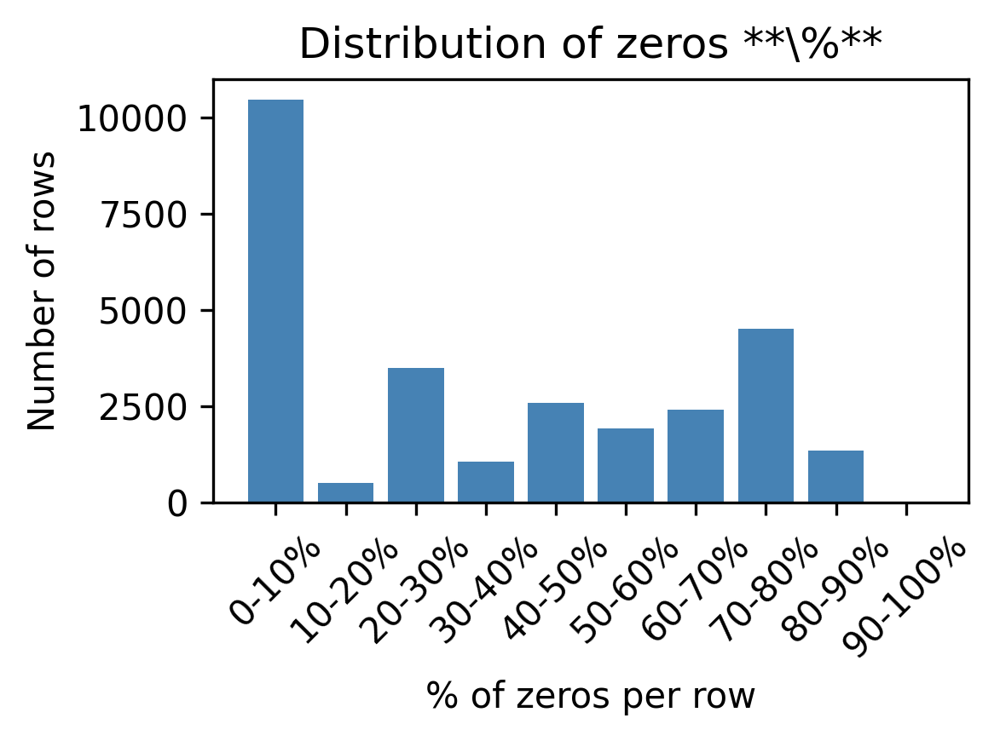

In [11]:
# df = seu dataset
approx_counts = summarize_zeros(df)


#### 2.4 Filtering >30% Zeros in the data

In [12]:

# Display the initial number of rows.
print('The current number of rows is ' + str(df.shape[0]))

# Retain rows with at least 70% non-zero values.
df = df[(df != 0).mean(axis=1) >= 0.7]

print('Number of rows after removing those with >30% zeros: ' + str(df.shape[0]))

# Apply log2 transformation, replacing zeros with NaN to avoid -inf values.
df = np.log2(df.replace(0, np.nan))

df.head()

# Export the filtered and log2-transformed dataset.
df.to_csv(
    r'Phosphoproteome/output_files/01_Phospho_(STY)Sites_PIF_0.5_cleanLog2.tsv',
    sep='\t',
    decimal='.'
)


The current number of rows is 88689
Number of rows after removing those with >30% zeros: 14512


#### Check 1: Histogram and Boxplot of the Data

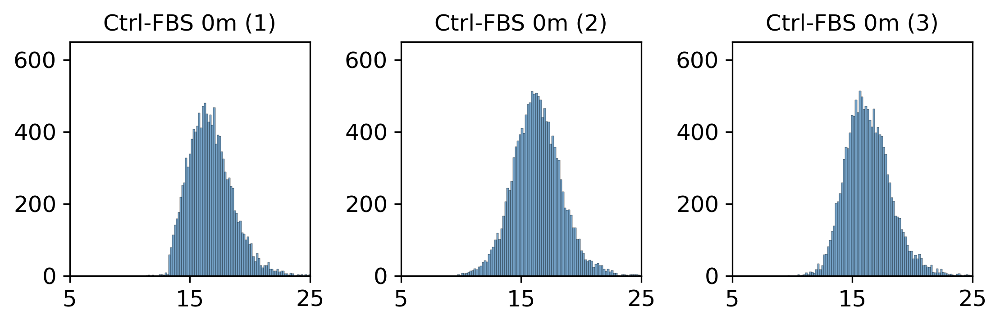

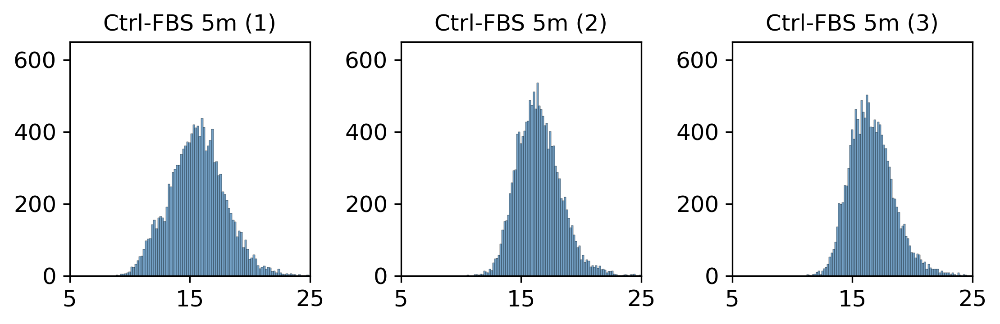

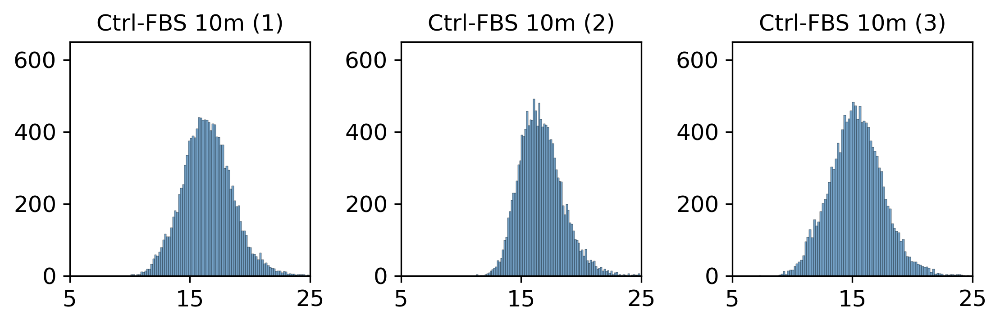

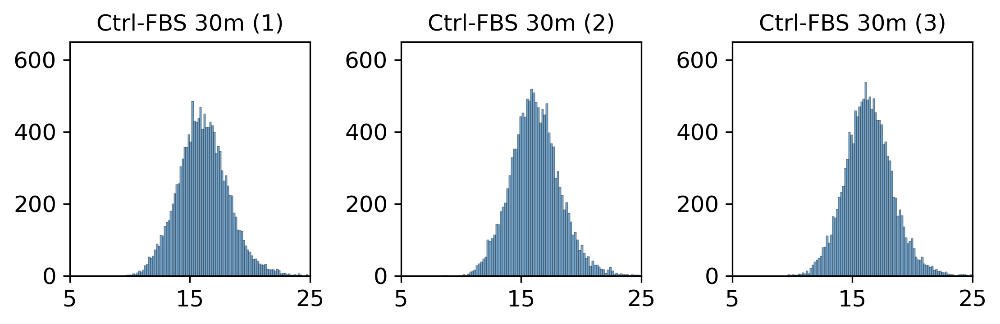

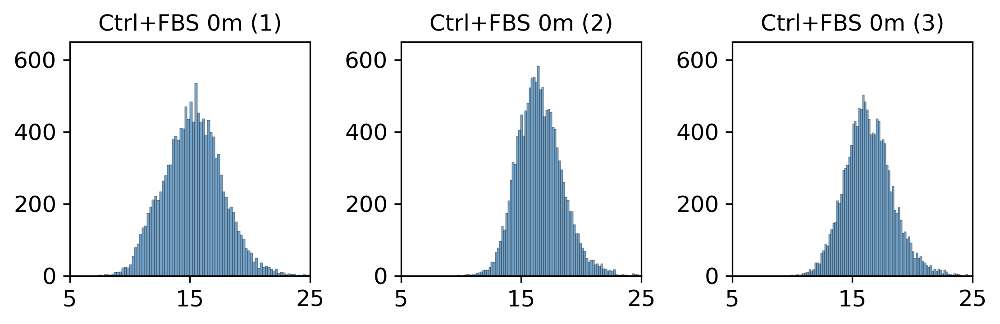

...

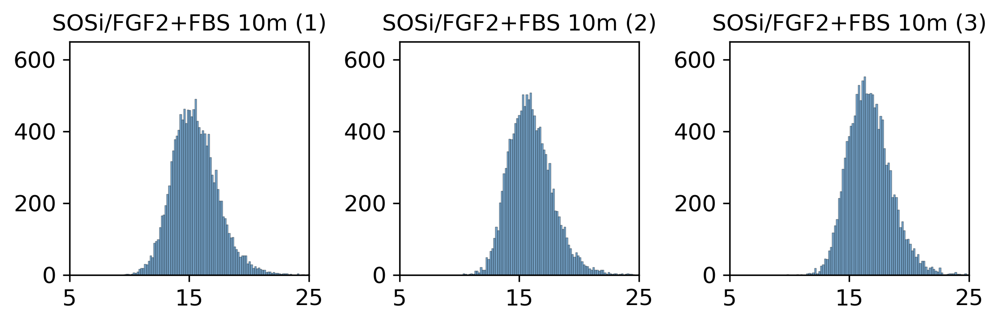

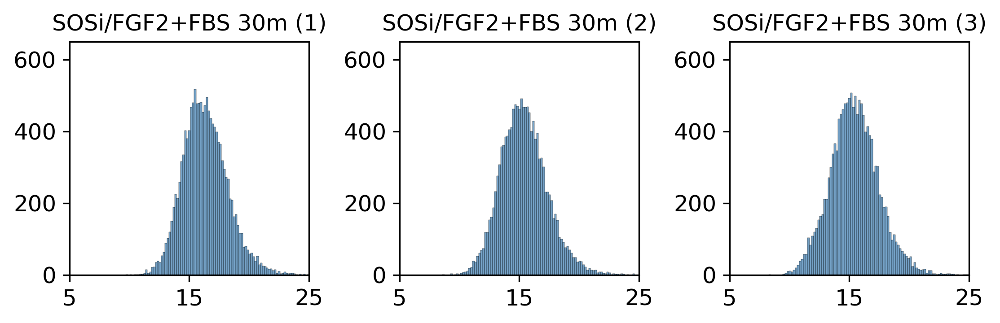

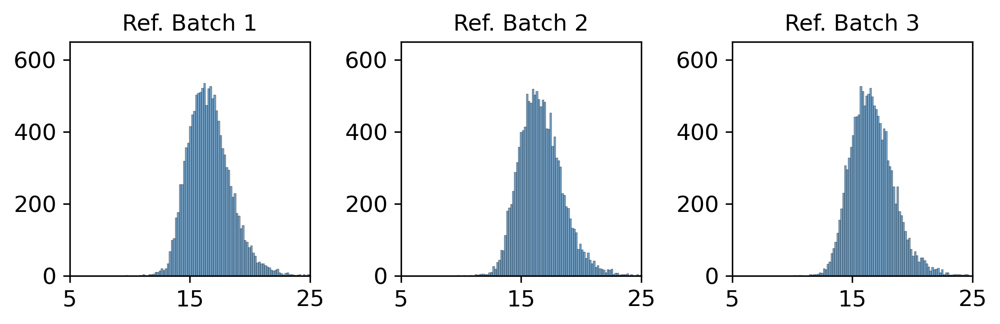

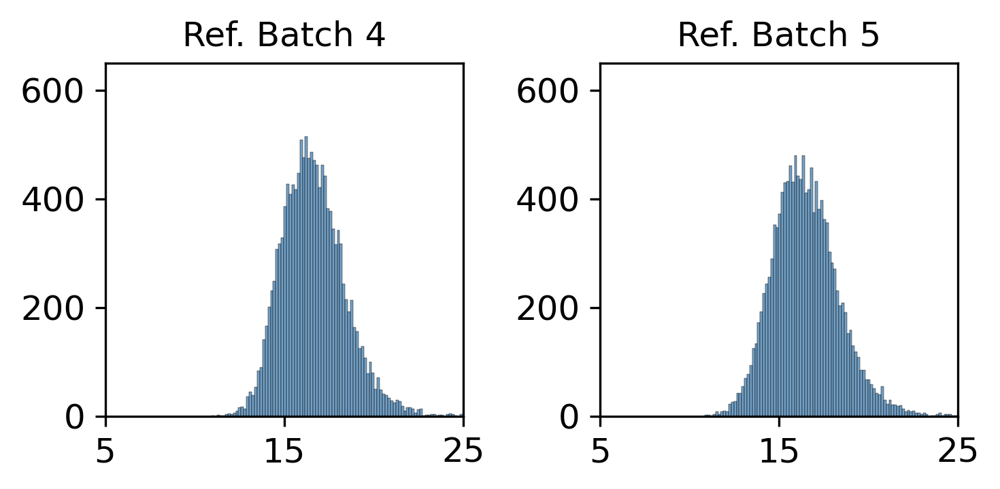

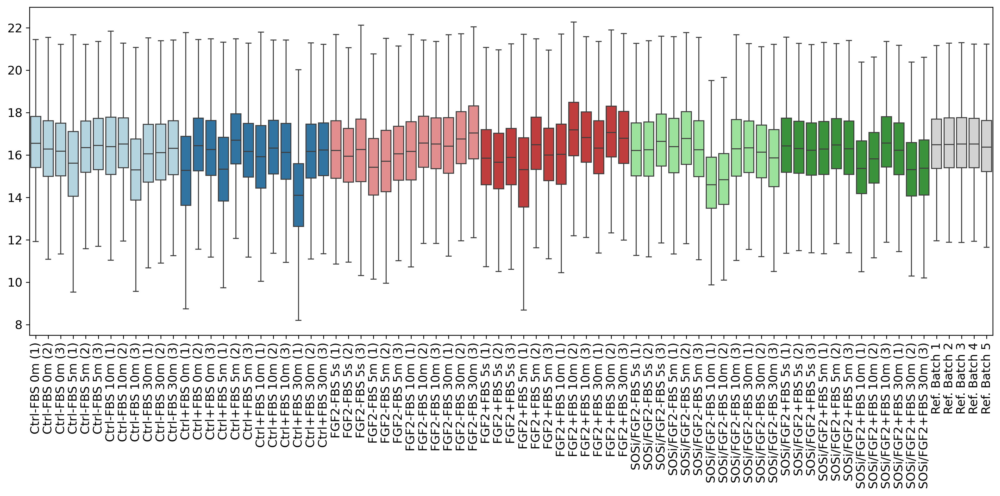

In [13]:

# Generate individual histograms to inspect intensity distributions across samples.
plot_histograms(
    df=df,
    individual=True,
    grouped=False,
    include_zeros=True,
    rename_dict=sampleName_Dict,
    xlim=[5, 25],
    ylim=[0, 650],
    xticksDisplayed=[5, 15, 25],
    yticksDisplayed=None,
    xlabel=None,
    ylabel=None,
    title=None,
    title_size=12,
    xtick_labelsize=12,  # Font size of x-axis tick labels.
    ytick_labelsize=12,  # Font size of y-axis tick labels.
    xlabel_size=12,      # Font size of the x-axis label.
    ylabel_size=12       # Font size of the y-axis label.
)


# Generate boxplots to compare intensity distributions across samples.
plot_boxplot(
    df=df,
    title=None,
    rename_dict=sampleName_Dict,
    block_size=12,
    gray_count=5,
    title_size=14,            # Font size of the main title.
    xtick_labelsize=12,       # Font size of x-axis tick labels.
    ytick_labelsize=12,       # Font size of y-axis tick labels.
    xlabel=None,              # Optional x-axis label.
    ylabel=None,              # Optional y-axis label.
    xlabel_size=12,           # Font size of the x-axis label.
    ylabel_size=12            # Font size of the y-axis label.
)


#### 2.5 Replacing Missing inputs with BPCA

##### 2.5.1 Visualizing the Actual Missing Pattern

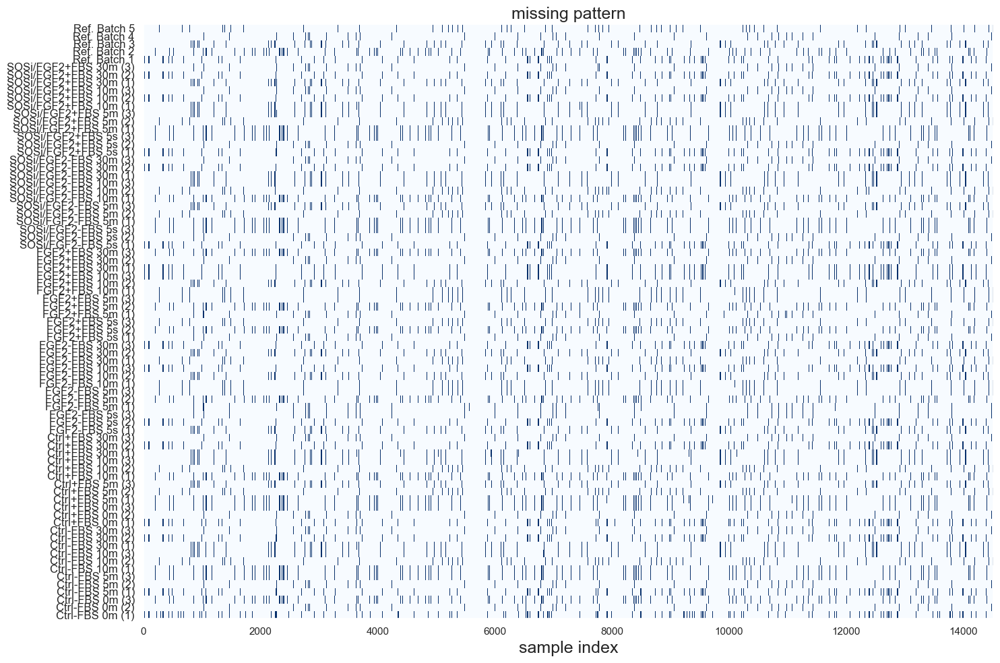

In [14]:
# NOTE:
# The BPCA imputation implementation used in this workflow is based on the
# Python adaptation by Kitamoto et al. (2023).
# This implementation is not included in this repository.
# Before running this section, clone or download the original repository:
# https://github.com/Idesan/bpca
# Follow the installation and usage instructions provided in that repository.

import sys
sys.path.append(r"outer_functions/bpca_impute")
sys.path.append(r"outer_functions/bpca_impute_util")

import bpca_impute
import bpca_impute_util

# Generate the missing-value pattern visualization
df_renamed = df.rename(columns=sampleName_Dict)

_, _ = bpca_impute_util.show_missing_pattern_binary(df_renamed, figsize=(15,10))

##### 2.5.2 Applying BPCA

In [15]:
# Convert DataFrame to numpy array with shape: features x samples
data_matrix = df.to_numpy().T  

# imputed_matrix, param = bpca_impute.impute_bpca_ard(
#     data_matrix,
#     n_PCs=15,      
#     eps=1e-4,        
#     a_min=1e-5,       
#     itr_max=200,     
#     err_L_th=1e-5,    
#     err_x_th=1e-5,   
#     verbose=True
# )

imputed_matrix, param = bpca_impute.impute_bpca_ard(
    data_matrix,
    n_PCs=35,         # latent dimensions suficientes para manter variabilidade
    eps=1e-4,         # mantém ruído baixo, não suaviza demais
    a_min=1e-5,       # evita remover dimensões que ainda carregam informação
    itr_max=1000,     # mais iterações para convergência fina
    err_L_th=1e-5,    # critério de log-likelihood rigoroso
    err_x_th=1e-5,    # critério de erro de missing rigoroso
    verbose=True
)

# Convert back to DataFrame: samples as columns, features as rows
df_bpca_imputed = pd.DataFrame(imputed_matrix.T, columns=df.columns, index=df.index)




#samples=14512, obs.dim=77, initial latent dim=35
 100: err_L=0.000250, err_x=0.000312
 200: err_L=0.000063, err_x=0.000152
 300: err_L=0.000019, err_x=0.000082
 400: err_L=0.000010, err_x=0.000055
 500: err_L=0.000006, err_x=0.000042
 600: err_L=0.000004, err_x=0.000034
 700: err_L=0.000003, err_x=0.000029
 800: err_L=0.000003, err_x=0.000025
 900: err_L=0.000002, err_x=0.000023
1000: err_L=0.000002, err_x=0.000021
Finished ARD_BPCA:itr=1000, err_L=1.9926597857793666e-06, err_x=2.1143714561056966e-05


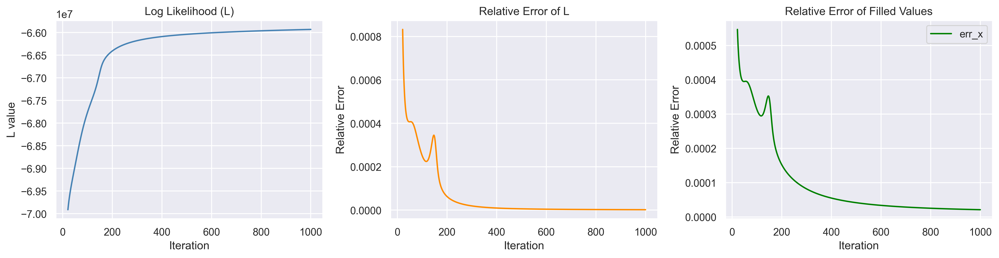

In [16]:
# Extract parameters safely
W = param.get('W')
Z = param.get('Z')
Adiag = param.get('Adiag')
mu = param.get('mu')
err_x = param.get('err_x')
err_W = param.get('err_W', None)  # None if not present
err_L = param.get('err_L', None)
loglik = param.get('loglik', None)

# Create iteration sequence
itr_sequence = np.arange(1, len(err_x)+1)
itr0 = 20  # skip first few iterations for clarity

# Plot all together
fig, ax = plt.subplots(1, 3, figsize=(15,4), dpi=300, sharex=False)

# 1) Log-likelihood
if loglik is not None:
    ax[0].plot(itr_sequence[itr0:], loglik[itr0:], color='steelblue')
    ax[0].set_title('Log Likelihood (L)')
    ax[0].set_xlabel('Iteration')
    ax[0].set_ylabel('L value')

# 2) Relative error of L
if err_L is not None:
    ax[1].plot(itr_sequence[itr0:], err_L[itr0:], color='darkorange')
    ax[1].set_title('Relative Error of L')
    ax[1].set_xlabel('Iteration')
    ax[1].set_ylabel('Relative Error')

# 3) Relative error of filled values (err_x) and optionally err_W
ax[2].plot(itr_sequence[itr0:], err_x[itr0:], label='err_x', color='green')
if err_W is not None:
    ax[2].plot(itr_sequence[itr0:], err_W[itr0:], label='err_W', color='red')
ax[2].set_title('Relative Error of Filled Values')
ax[2].set_xlabel('Iteration')
ax[2].set_ylabel('Relative Error')
ax[2].legend()

fig.tight_layout()
plt.show()

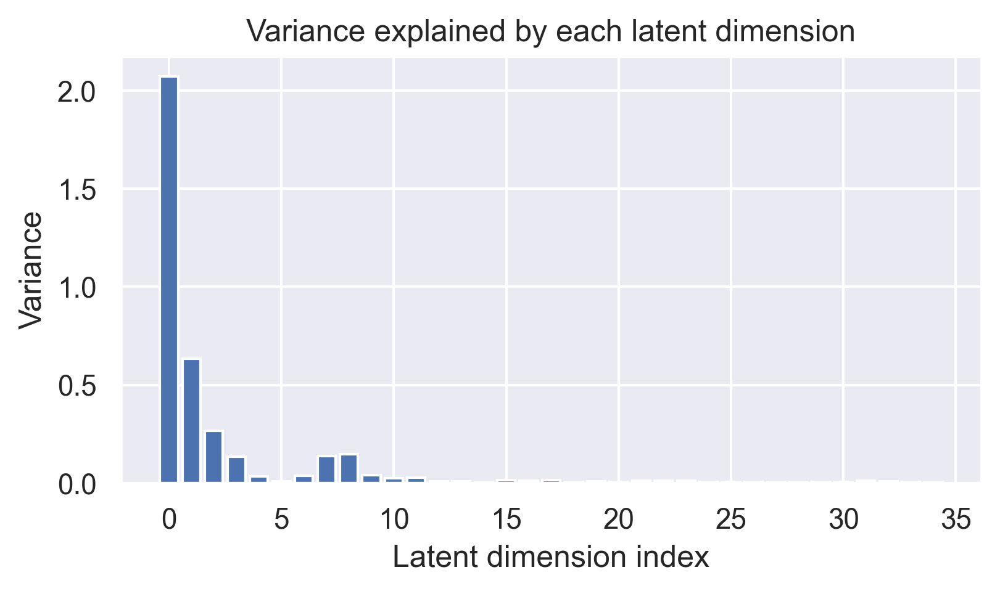

In [17]:
# Adiag contém a variância explicada por cada dimensão latente
plt.figure(figsize=(6,3), dpi=300)
plt.bar(np.arange(len(Adiag)), Adiag)
plt.xlabel("Latent dimension index")
plt.ylabel("Variance")
plt.title("Variance explained by each latent dimension")
plt.show()


In [18]:
for i, v in enumerate(Adiag):
    print(f"PC{i+1}: variance = {v:.6f}")


PC1: variance = 2.073251
PC2: variance = 0.634573
PC3: variance = 0.265408
PC4: variance = 0.134777
PC5: variance = 0.033469
PC6: variance = 0.009348
PC7: variance = 0.035914
PC8: variance = 0.136472
PC9: variance = 0.146061
PC10: variance = 0.039405
PC11: variance = 0.025799
PC12: variance = 0.028162
PC13: variance = 0.007875
PC14: variance = 0.007673
PC15: variance = 0.007011
PC16: variance = 0.013539
PC17: variance = 0.010285
PC18: variance = 0.015776
PC19: variance = 0.006243
PC20: variance = 0.009028
PC21: variance = 0.005079
PC22: variance = 0.010214
PC23: variance = 0.012962
PC24: variance = 0.012096
PC25: variance = 0.004567
PC26: variance = 0.005250
PC27: variance = 0.006839
PC28: variance = 0.005860
PC29: variance = 0.005478
PC30: variance = 0.006318
PC31: variance = 0.005688
PC32: variance = 0.011514
PC33: variance = 0.009102
PC34: variance = 0.004955
PC35: variance = 0.005987


##### 2.5.3 To show that there is no missing inputs anymore

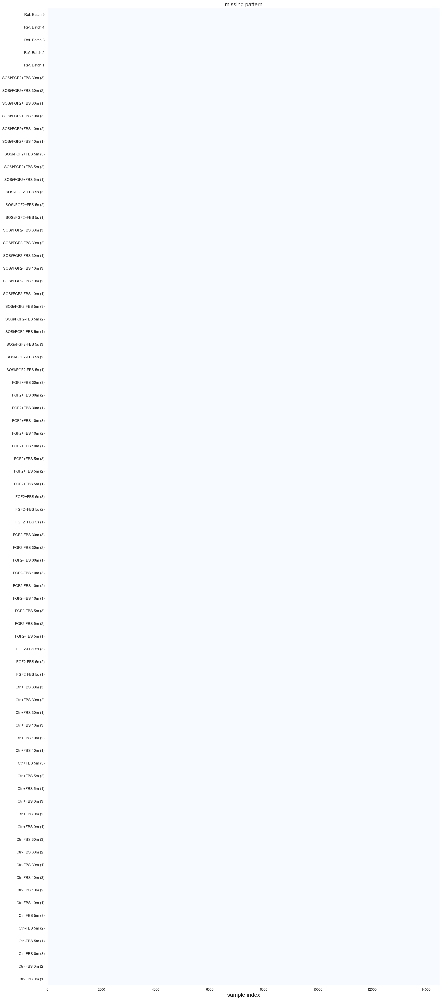

In [19]:
df_imputed_renamed = df_bpca_imputed.rename(columns=sampleName_Dict)

_, _ = bpca_impute_util.show_missing_pattern_binary(df_imputed_renamed, figsize=(20,45))

#### Check 2: Histogram and Boxplot of the Data after BPCA

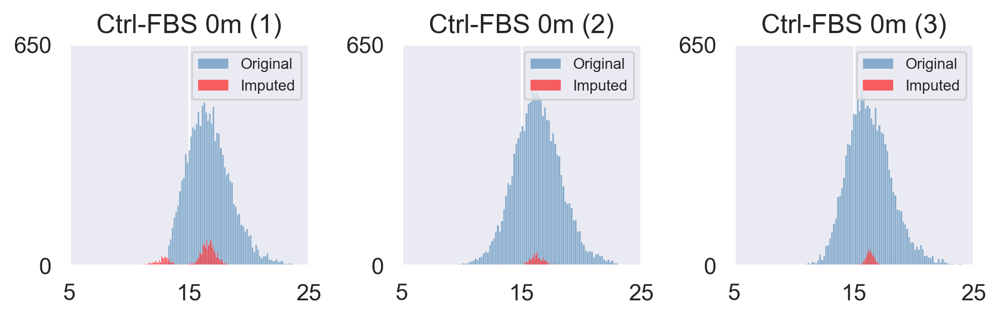

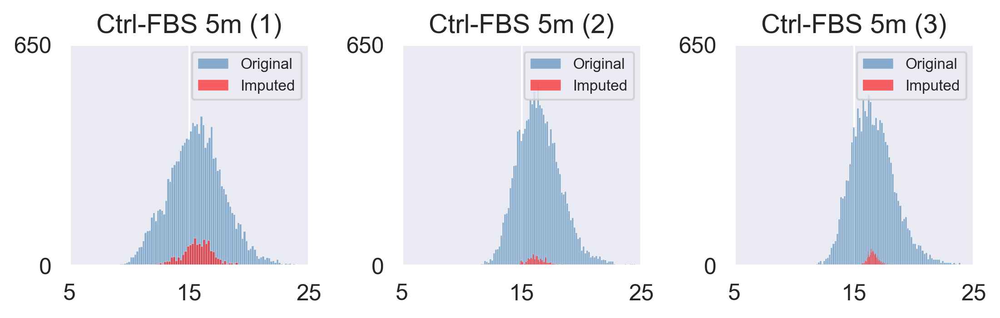

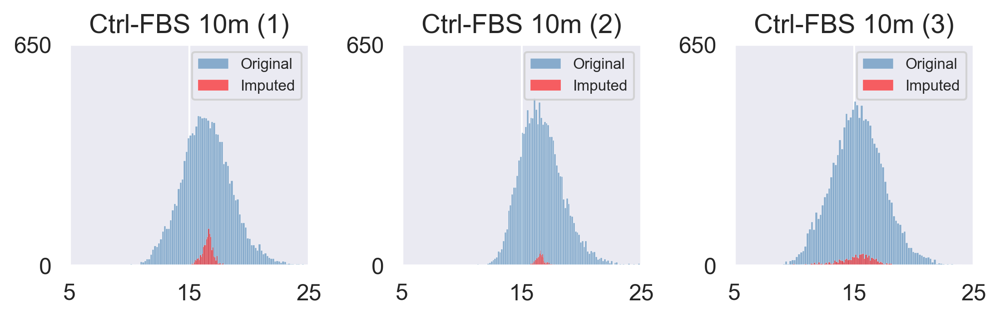

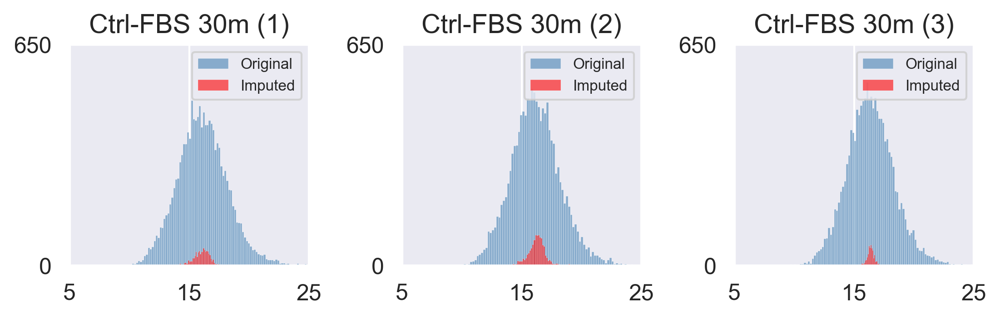

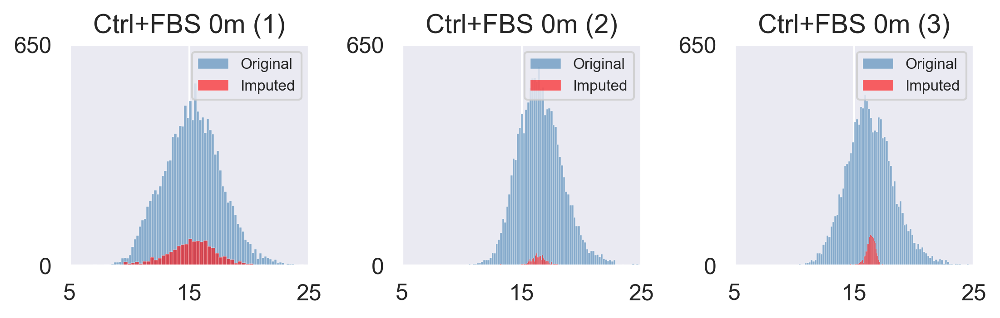

...

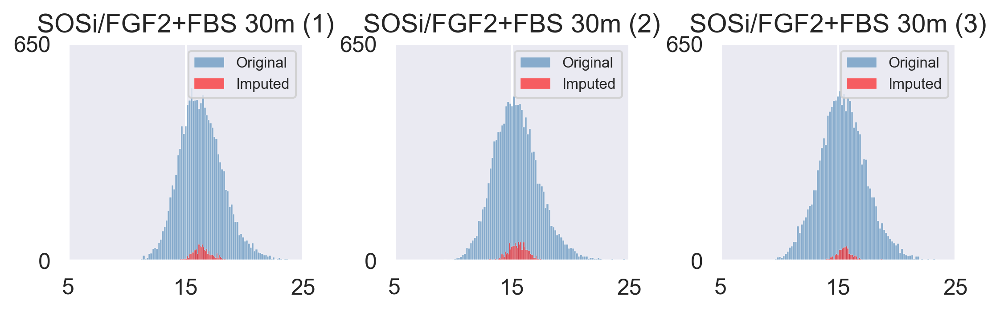

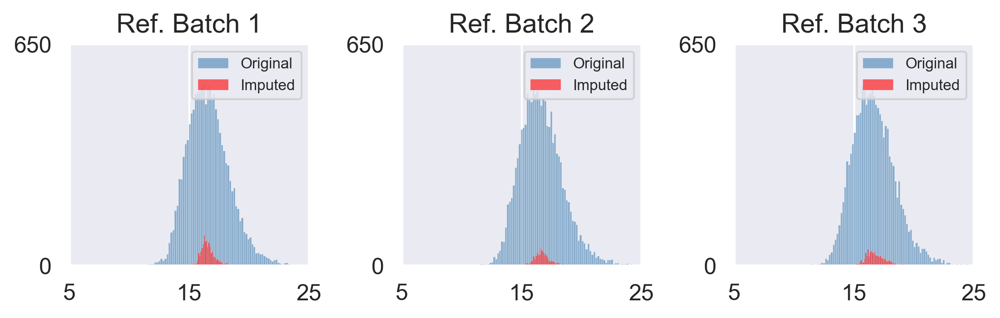

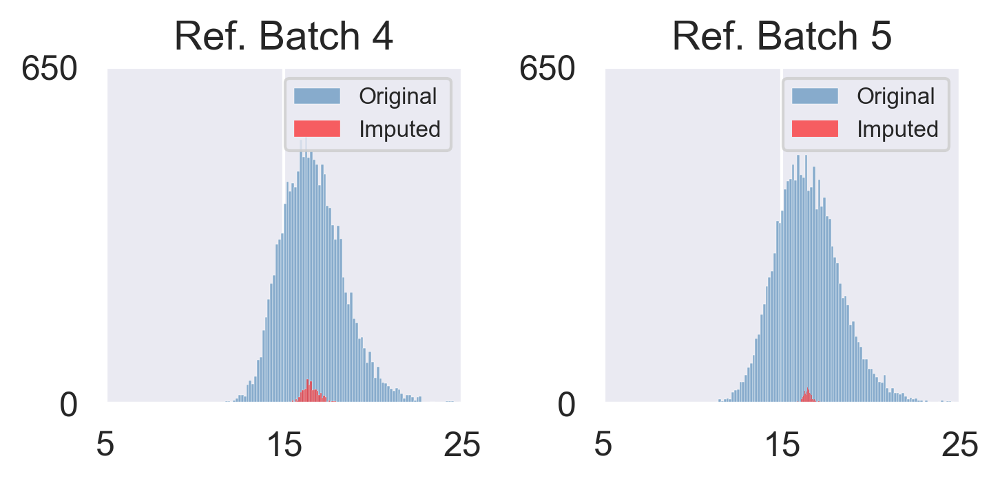

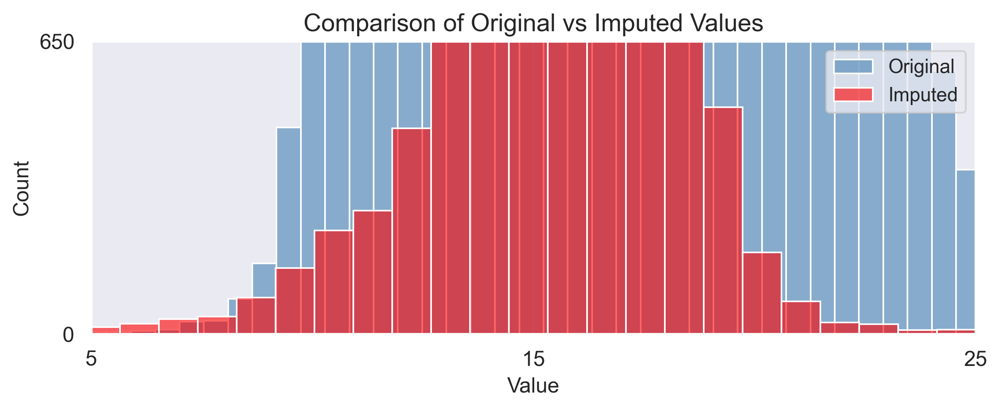

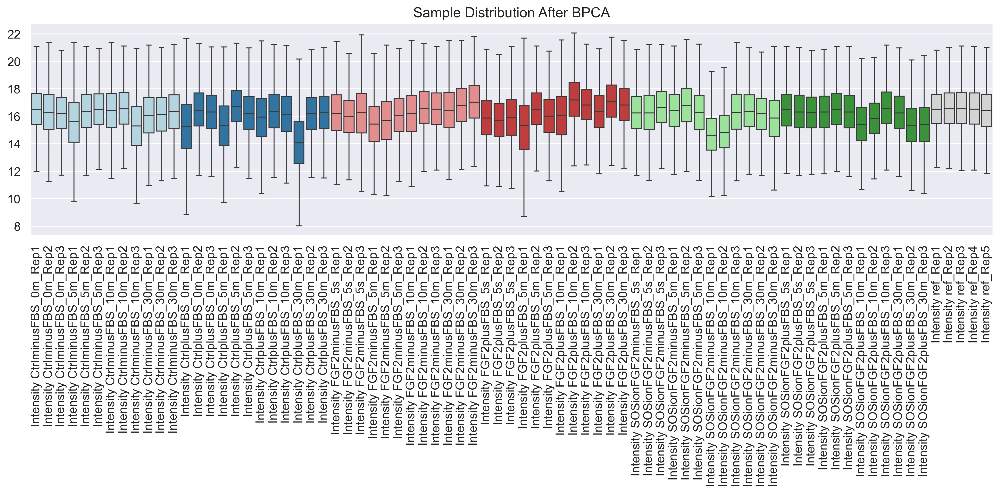

In [20]:

# Compare intensity distributions before and after BPCA imputation.
plot_histograms_compare(
    df_original=df,                    # Original DataFrame before imputation, containing NaN values.
    df_imputed=df_bpca_imputed,        # DataFrame after imputation.
    individual=True,                   # Generate separate histograms for each sample.
    grouped=True,                      # Generate a combined histogram across all samples.
    include_zeros=False,               # Exclude zero values from the histograms.
    rename_dict=sampleName_Dict,       # Apply concise sample names for plot labels.
    xlim=[5, 25],                      # Optional x-axis limits.
    ylim=[0, 650],                     # Optional y-axis limits.
    xlabel=None,                       # Optional x-axis label.
    ylabel=None,                       # Optional y-axis label.
    title="Comparison of Original vs Imputed Values",
    title_size=14,
    xtick_labelsize=12,                # Font size of x-axis tick labels.
    ytick_labelsize=12,                # Font size of y-axis tick labels.
    xlabel_size=12,                    # Font size of the x-axis label.
    ylabel_size=12                     # Font size of the y-axis label.
)


# Visualize sample intensity distributions after BPCA imputation.
plot_boxplot(
    df=df_bpca_imputed,
    title="Sample Distribution After BPCA",
    rename_dict=None,
    block_size=12,
    gray_count=5,
    title_size=14,            # Font size of the main title.
    xtick_labelsize=12,       # Font size of x-axis tick labels.
    ytick_labelsize=12,       # Font size of y-axis tick labels.
    xlabel=None,              # Optional x-axis label.
    ylabel=None,              # Optional y-axis label.
    xlabel_size=12,           # Font size of the x-axis label.
    ylabel_size=12            # Font size of the y-axis label.
)


## Step 3: comBat Function


#### 3.1 Applying cOmbat

In [21]:
# NOTE:
# Batch correction is performed using the ComBat method through the
# pycombat implementation provided by the combat Python package.
# The package is imported directly and is not included in this repository.
# Please install the package in your Python environment before running
# this section.

# Define the ComBat batch-correction workflow.
# The function uses the phosphoproteomics data and batch metadata
# to perform batch correction and generate the corrected dataset.

from combat.pycombat import pycombat
import re
from collections import defaultdict


# ---------------------------------------------------------
# 1. Validate the input data
# ---------------------------------------------------------

print("df (data):\n", df_bpca_imputed.head())
print("batch_info_dataframe (batch info):\n", batch_info_dataframe.head())


# ---------------------------------------------------------
# 2. Extract batch and covariate information
# ---------------------------------------------------------

batch = batch_info_dataframe.iloc[0, :].tolist()

covariates = None
if batch_info_dataframe.shape[0] > 1:
    covariates = batch_info_dataframe.iloc[1, :].tolist()

    # Optionally display the distribution of covariate values.
    counted = defaultdict(int)
    for val in covariates:
        counted[val] += 1

    print("Covariate distribution:\n", dict(counted))


# Display input dimensions and metadata lengths for validation.
print("df shape:", df_bpca_imputed.shape)
print("batch length:", len(batch))
print(
    "covariates length:",
    len(covariates) if covariates else "None"
)


# ---------------------------------------------------------
# 3. Apply ComBat batch correction
# ---------------------------------------------------------

df_corrected = pycombat(
    df_bpca_imputed,
    batch=batch,
    mod=covariates
)

df_corrected.describe()


df (data):
       Intensity CtrlminusFBS_0m_Rep1  Intensity CtrlminusFBS_0m_Rep2  \
ID                                                                     
UID1                       15.454746                       11.401306   
UID4                       13.768184                       12.973231   
UID5                       15.624738                       15.560542   
UID8                       16.595374                       15.590412   
UID9                       17.388206                       14.124202   

      Intensity CtrlminusFBS_0m_Rep3  Intensity CtrlminusFBS_5m_Rep1  \
ID                                                                     
UID1                       12.157347                       14.131312   
UID4                       14.604148                       11.295941   
UID5                       15.397574                       14.627648   
UID8                       15.915856                       15.884695   
UID9                       14.274233               

,Intensity CtrlminusFBS_0m_Rep1,Intensity CtrlminusFBS_0m_Rep2,Intensity CtrlminusFBS_0m_Rep3,Intensity CtrlminusFBS_5m_Rep1,Intensity CtrlminusFBS_5m_Rep2,Intensity CtrlminusFBS_5m_Rep3,Intensity CtrlminusFBS_10m_Rep1,Intensity CtrlminusFBS_10m_Rep2,Intensity CtrlminusFBS_10m_Rep3,Intensity CtrlminusFBS_30m_Rep1,...,Intensity SOSionFGF2plusFBS_10m_Rep2,Intensity SOSionFGF2plusFBS_10m_Rep3,Intensity SOSionFGF2plusFBS_30m_Rep1,Intensity SOSionFGF2plusFBS_30m_Rep2,Intensity SOSionFGF2plusFBS_30m_Rep3,Intensity ref_Rep1,Intensity ref_Rep2,Intensity ref_Rep3,Intensity ref_Rep4,Intensity ref_Rep5
count,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,...,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000,14512.000000
mean,16.520890,16.317339,16.349324,16.029274,16.402216,16.542649,16.408341,16.520904,15.615105,16.178052,...,16.035507,16.515389,16.173305,15.636414,15.469690,16.637866,16.657436,16.684153,16.610664,16.493797
std,1.733620,1.824962,1.713917,1.870181,1.640668,1.641357,1.889024,1.661641,1.972016,1.864871,...,1.606687,1.606276,1.669102,1.737928,1.828998,1.573188,1.592675,1.585256,1.579232,1.644464
min,10.802952,10.251340,11.064813,8.252366,10.379670,11.148756,10.281459,11.314830,8.466651,10.449533,...,10.627390,11.325656,10.523713,8.969069,9.219307,11.558014,11.071505,10.619877,11.243782,11.122360
25%,15.407149,15.203146,15.215612,14.789651,15.287977,15.415661,15.236349,15.379772,14.346770,14.997655,...,14.929764,15.391626,15.033073,14.483567,14.305982,15.554059,15.554456,15.576562,15.515681,15.374585
50%,16.318423,16.147055,16.131849,15.894315,16.171884,16.292907,16.304835,16.274514,15.559708,16.045455,...,15.800042,16.262663,15.954453,15.466297,15.344158,16.376645,16.405665,16.430563,16.355521,16.270518
75%,17.457749,17.337605,17.279088,17.100902,17.296934,17.425272,17.502825,17.416277,16.774602,17.256816,...,16.923897,17.400315,17.097208,16.616848,16.517655,17.478585,17.520118,17.538683,17.457776,17.409084
max,26.082676,25.850055,25.690811,25.639250,25.475738,25.793387,25.940315,25.976200,25.217766,25.805038,...,25.249927,25.512430,25.554027,25.027734,24.933272,25.533645,25.624095,25.527372,25.535123,25.783806


#### 3.2 After Combat

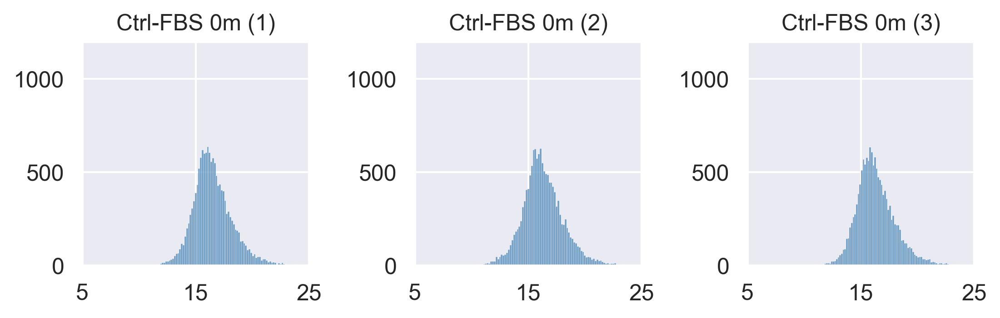

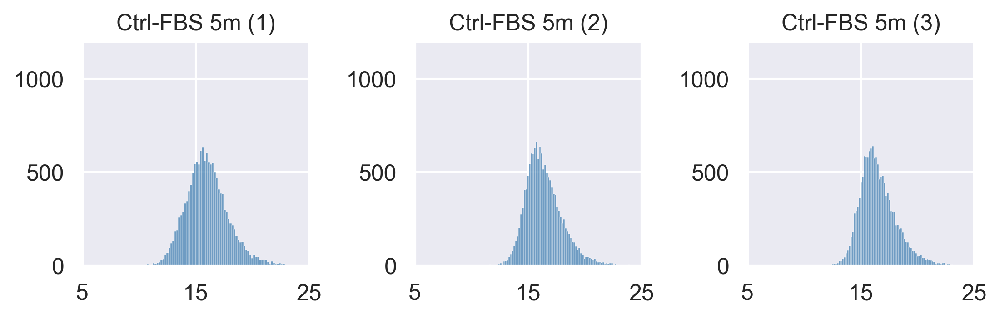

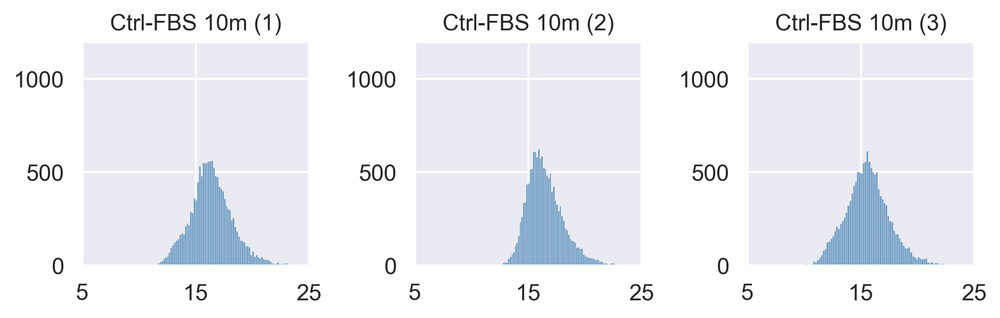

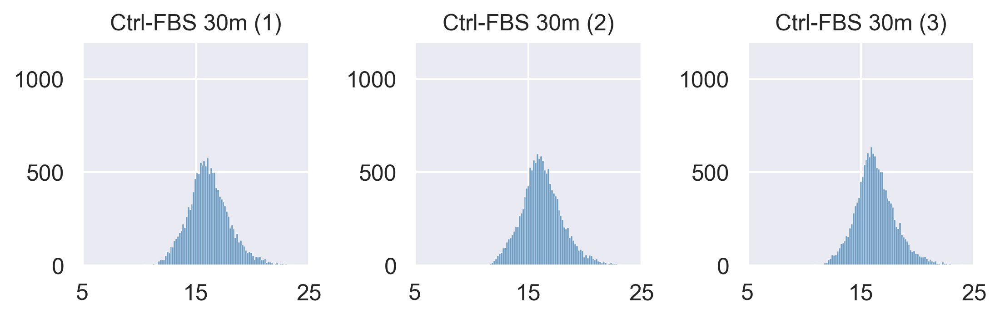

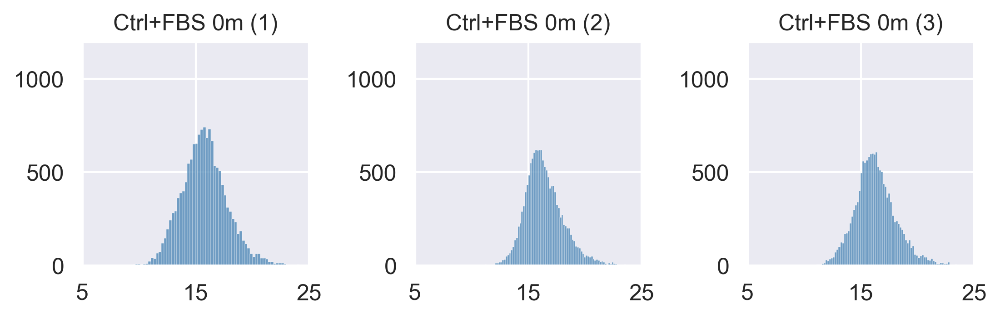

...

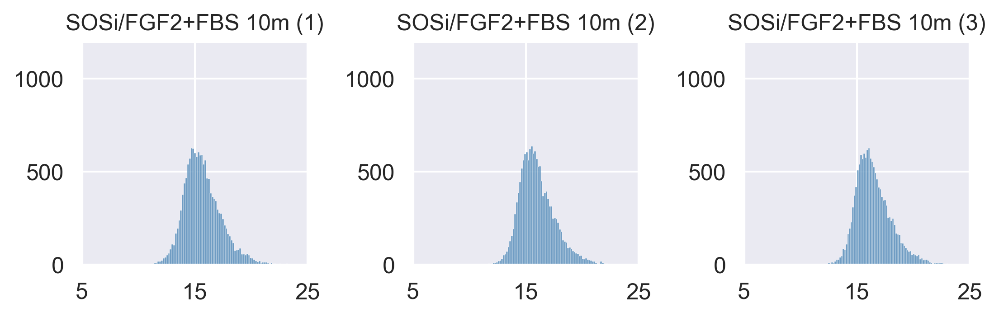

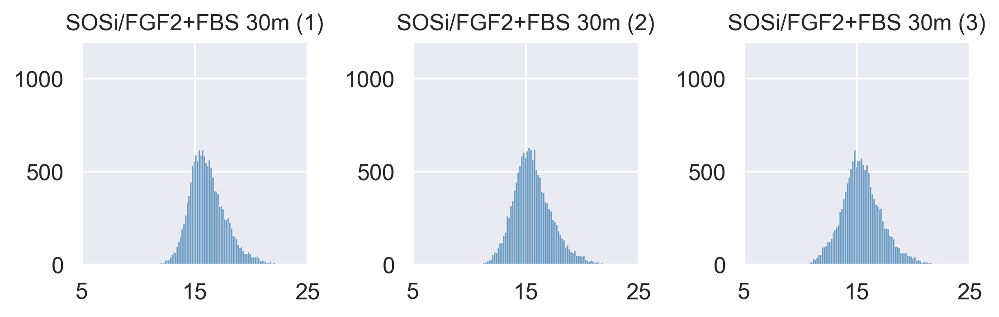

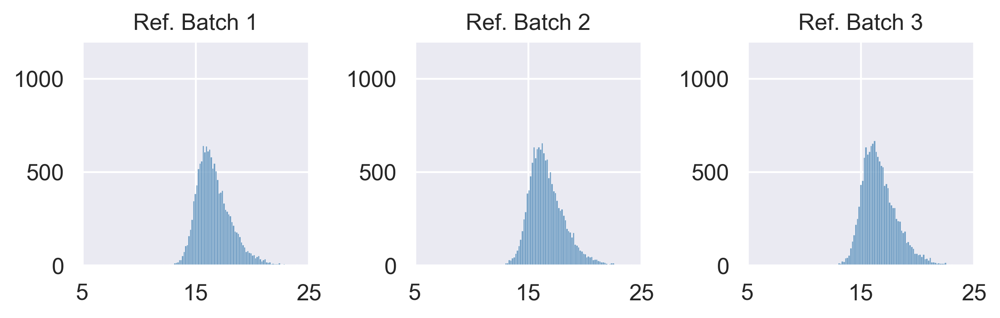

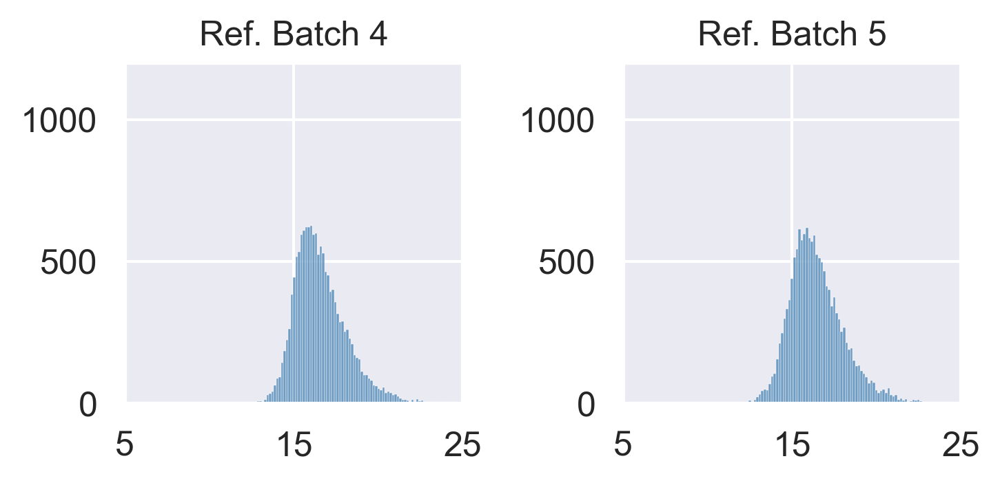

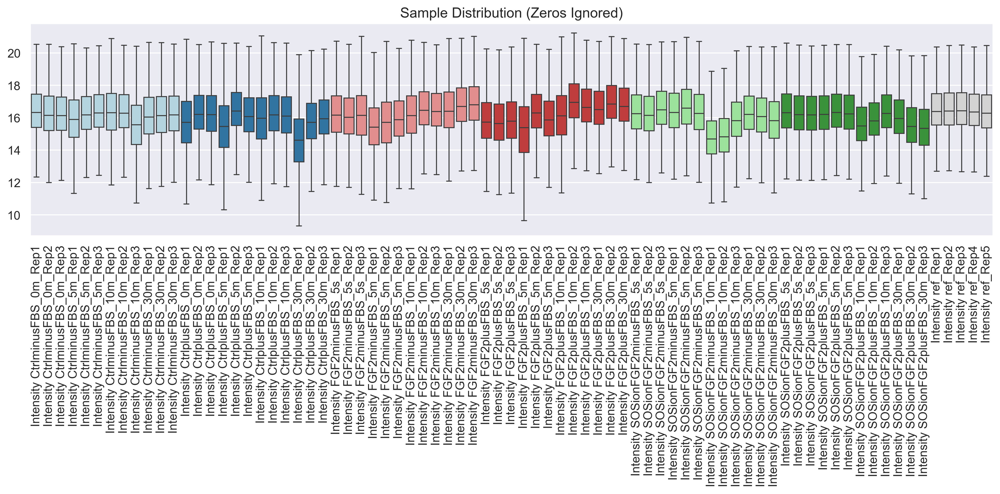

In [22]:
# Inspect intensity distributions across samples after ComBat batch correction.
plot_histograms(
    df=df_corrected,
    individual=True,
    grouped=False,
    include_zeros=True,
    rename_dict=sampleName_Dict,
    xlim=[5, 25],
    ylim=[0, 1200],
    xticksDisplayed=[5, 15, 25],
    yticksDisplayed=None,
    xlabel=None,
    ylabel=None,
    title=None,
    title_size=12,
    xtick_labelsize=12,  # Font size of x-axis tick labels.
    ytick_labelsize=12,  # Font size of y-axis tick labels.
    xlabel_size=12,      # Font size of the x-axis label.
    ylabel_size=12       # Font size of the y-axis label.
)


# Compare sample intensity distributions after ComBat batch correction.
plot_boxplot(
    df=df_corrected,
    title="Sample Distribution (Zeros Ignored)",
    rename_dict=None,
    block_size=12,
    gray_count=5,
    title_size=14,            # Font size of the main title.
    xtick_labelsize=12,       # Font size of x-axis tick labels.
    ytick_labelsize=12,       # Font size of y-axis tick labels.
    xlabel=None,              # Optional x-axis label.
    ylabel=None,              # Optional y-axis label.
    xlabel_size=12,           # Font size of the x-axis label.
    ylabel_size=12            # Font size of the y-axis label.
)



#### 3.3 Centering the Data

In [23]:

from sklearn.preprocessing import StandardScaler

# Center the data by subtracting the mean without scaling to unit variance.
scaler = StandardScaler(with_mean=True, with_std=False)

df_centered = pd.DataFrame(
    scaler.fit_transform(df_corrected),  # Use df or another processed DataFrame if needed.
    index=df.index,
    columns=df.columns
)

df_centered.head()



,Intensity CtrlminusFBS_0m_Rep1,Intensity CtrlminusFBS_0m_Rep2,Intensity CtrlminusFBS_0m_Rep3,Intensity CtrlminusFBS_5m_Rep1,Intensity CtrlminusFBS_5m_Rep2,Intensity CtrlminusFBS_5m_Rep3,Intensity CtrlminusFBS_10m_Rep1,Intensity CtrlminusFBS_10m_Rep2,Intensity CtrlminusFBS_10m_Rep3,Intensity CtrlminusFBS_30m_Rep1,...,Intensity SOSionFGF2plusFBS_10m_Rep2,Intensity SOSionFGF2plusFBS_10m_Rep3,Intensity SOSionFGF2plusFBS_30m_Rep1,Intensity SOSionFGF2plusFBS_30m_Rep2,Intensity SOSionFGF2plusFBS_30m_Rep3,Intensity ref_Rep1,Intensity ref_Rep2,Intensity ref_Rep3,Intensity ref_Rep4,Intensity ref_Rep5
ID,,,,,,,,,,,,,,,,,,,,,
UID1,-4.593666,-3.771735,-2.984669,-5.550538,-1.764946,-2.350041,-3.664120,-2.707158,-5.334882,-4.445261,...,-2.442529,-2.321553,-2.702655,-0.687039,-4.451180,-2.199226,-2.194676,-2.067276,-2.084129,-3.221641
UID4,-2.710989,-2.990359,-2.680361,-2.930035,-1.382302,-2.278657,-3.228534,-2.509788,-3.156145,-3.033867,...,-1.971305,-1.759567,-2.838617,-2.780336,-3.208988,-1.756114,-1.606651,-1.720066,-1.613201,-2.128108
UID5,-0.837642,-0.783573,-0.928528,-0.822108,-0.799964,-0.991058,-0.397645,-0.950544,-1.719786,-1.024900,...,-0.243045,-0.160020,-0.115793,-0.257852,-0.401737,-0.599360,-0.611216,-0.487176,-0.587240,-0.705014
UID8,-0.225190,-0.321407,-0.326607,-0.145765,-0.478011,-0.362942,-0.145708,-0.109397,0.320634,-0.270734,...,-0.361203,-0.079499,-0.370377,-0.133509,-0.226713,-0.402824,-0.226626,-0.445327,-0.436202,-0.367575
UID9,-0.558372,-1.549790,-1.614760,-2.100181,-1.702245,-1.513847,-1.224328,-1.091277,-0.822819,-1.288968,...,-0.974018,-1.234205,-1.340751,-2.048706,-1.046805,-1.106619,-1.267102,-1.396689,-1.786487,-1.266948


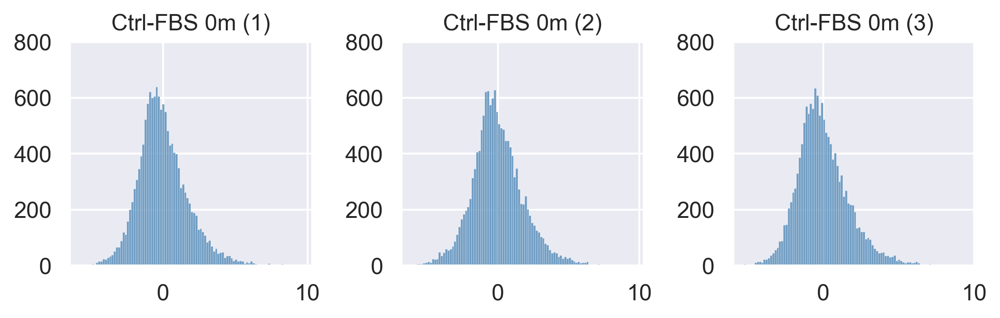

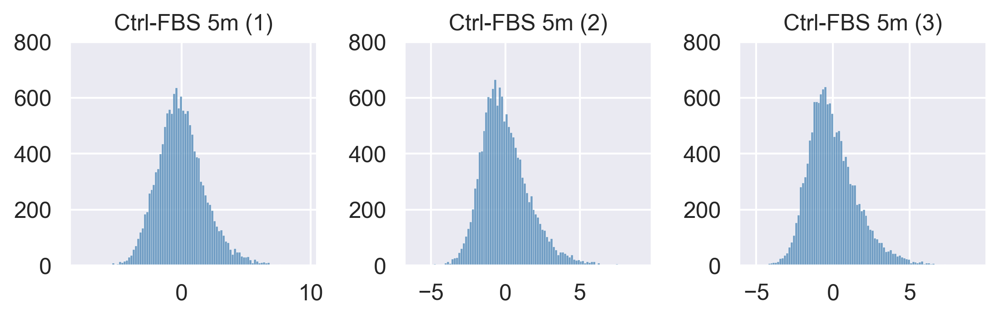

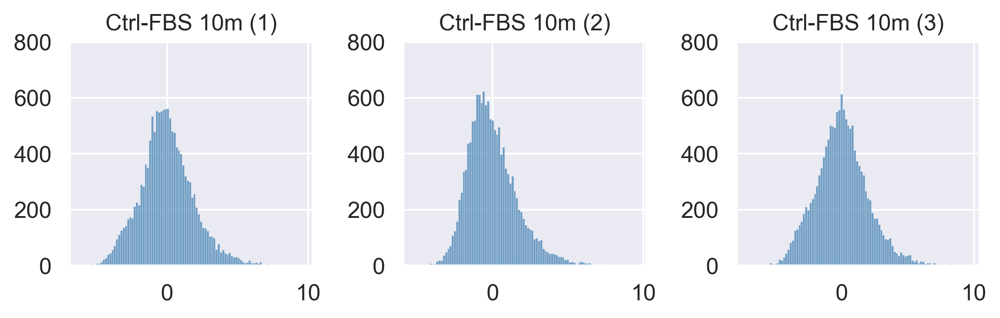

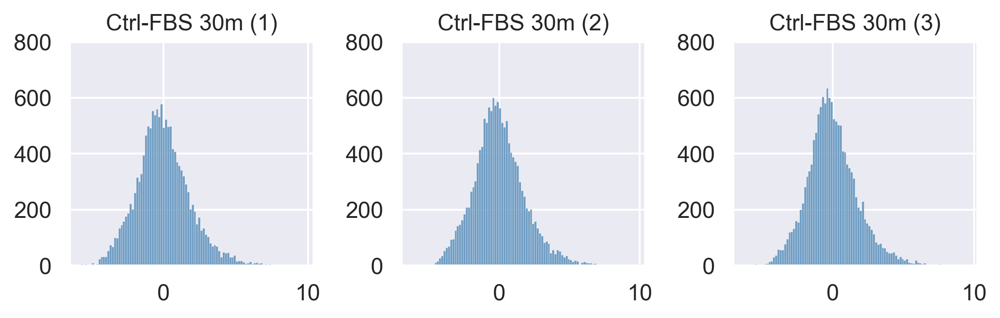

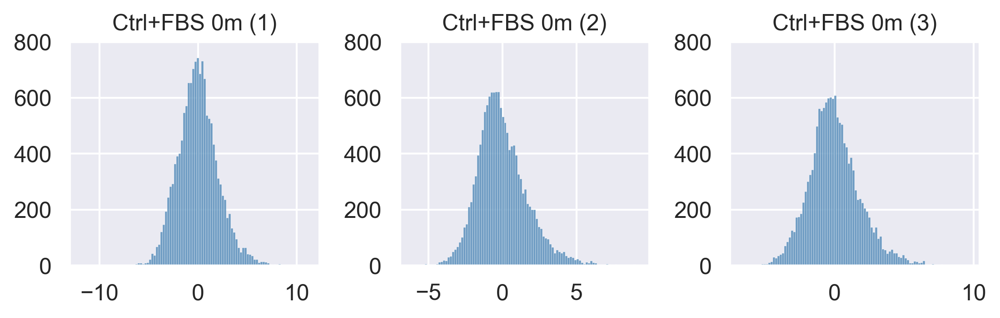

...

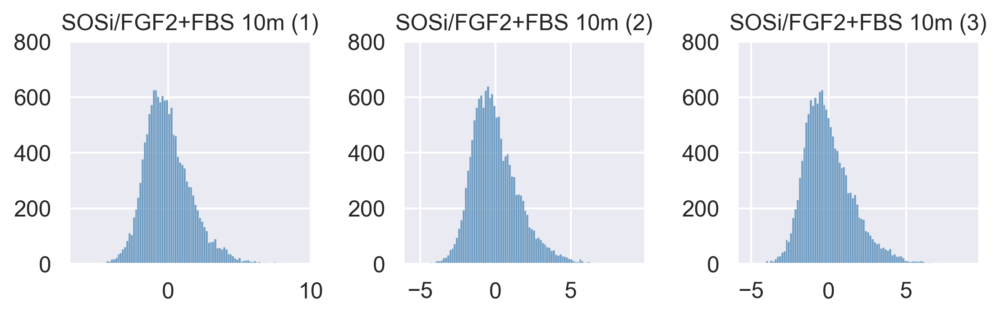

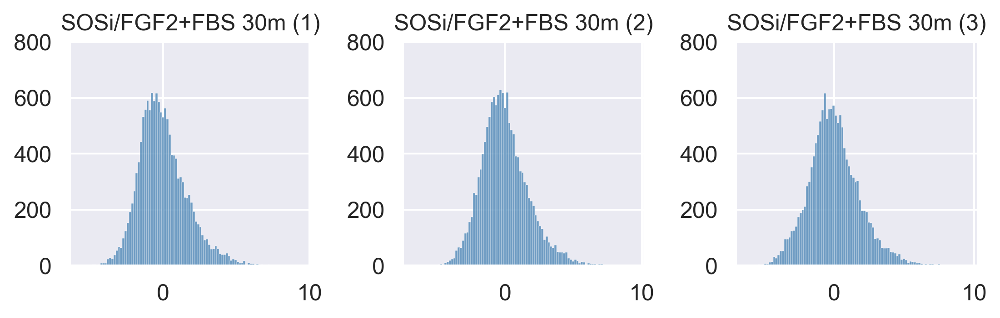

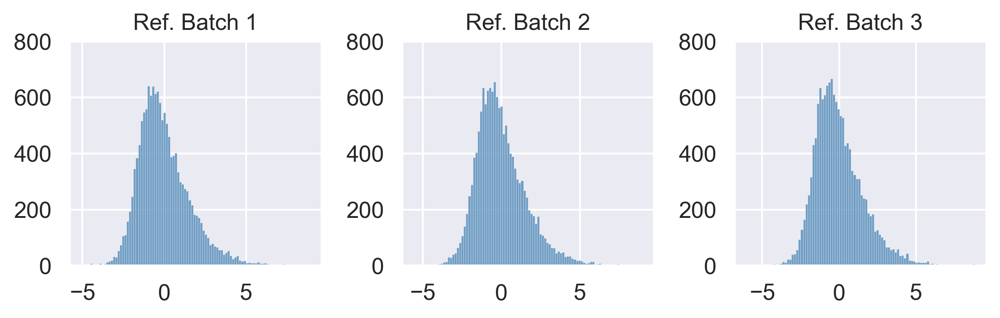

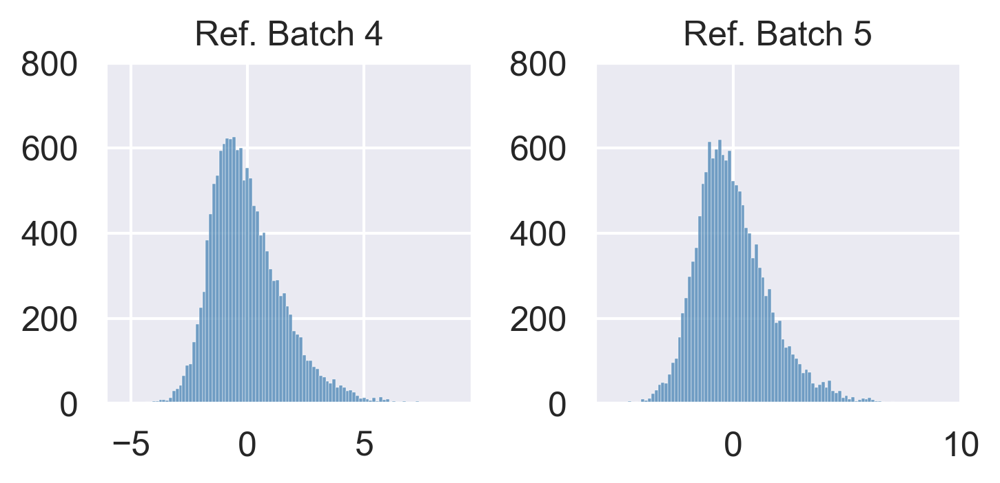

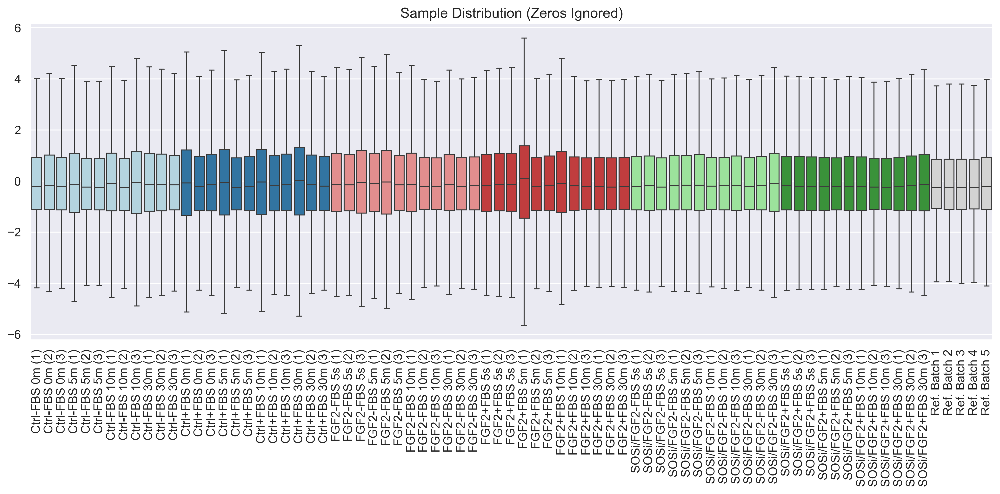

In [24]:

# Inspect intensity distributions across samples after mean-centering.
plot_histograms(
    df=df_centered,
    individual=True,
    grouped=False,
    include_zeros=True,
    rename_dict=sampleName_Dict,
    xlim=None,
    ylim=[0, 800],
    xticksDisplayed=None,
    yticksDisplayed=None,
    xlabel=None,
    ylabel=None,
    title=None,
    title_size=12,
    xtick_labelsize=12,  # Font size of x-axis tick labels.
    ytick_labelsize=12,  # Font size of y-axis tick labels.
    xlabel_size=12,      # Font size of the x-axis label.
    ylabel_size=12       # Font size of the y-axis label.
)


# Compare sample intensity distributions after mean-centering.
plot_boxplot(
    df=df_centered,
    title="Sample Distribution (Zeros Ignored)",
    rename_dict=sampleName_Dict,
    block_size=12,
    gray_count=5,
    title_size=14,            # Font size of the main title.
    xtick_labelsize=12,       # Font size of x-axis tick labels.
    ytick_labelsize=12,       # Font size of y-axis tick labels.
    xlabel=None,              # Optional x-axis label.
    ylabel=None,              # Optional y-axis label.
    xlabel_size=12,           # Font size of the x-axis label.
    ylabel_size=12            # Font size of the y-axis label.
)


#### 3.4 Saving All Files

In [25]:

# Export the BPCA-imputed phosphoproteomics dataset.
df_bpca_imputed.to_csv(
    r'Phosphoproteome/output_files/02_Phospho (STY)Sites_PIF_0.5_BPCA_NoRef.tsv',
    sep='\t',
    decimal='.'
)

# Export the BPCA-imputed dataset after ComBat batch correction.
df_corrected.to_csv(
    r'Phosphoproteome/output_files/03_Phospho (STY)Sites_PIF_0.5_BPCA_ComBat_NoRef.tsv',
    sep='\t',
    decimal='.'
)

# Export the BPCA-imputed and ComBat-corrected dataset after mean-centering.
df_centered.to_csv(
    r'Phosphoproteome/output_files/04_Phospho (STY)Sites_PIF_0.5_BPCA_ComBat_Centered_NoRef.tsv',
    sep='\t',
    decimal='.'
)


## Step 4: Concatenate with Maxquant Information

The cOmbat code does not allow all the information to be stored in the data file. This way it is needed to concatenate the inportant information that we have lost using the original file, joining by the unique identifier. 

In [26]:

# ---------------------------------------------------------
# 1. Load the original phosphosite metadata and processed data
# ---------------------------------------------------------

# Load the original rearranged MaxQuant phosphosite table.
old_file = pd.read_csv(
    r'Phosphoproteome/input_files/Phospho (STY)Sites_PIF_0.5_Rearranged.txt',
    sep='\t'
)

# Load the BPCA-imputed, ComBat-corrected, and mean-centered dataset.
new_file = pd.read_csv(
    r'Phosphoproteome/output_files/04_Phospho (STY)Sites_PIF_0.5_BPCA_ComBat_Centered_NoRef.tsv',
    sep='\t'
)


# ---------------------------------------------------------
# 2. Select the phosphosite metadata columns to retain
# ---------------------------------------------------------

old_file = old_file[[
    'C: Amino acid',
    'C: Charge',
    'C: Taxonomy IDs',
    'C: Taxonomy names',
    'C: Reverse',
    'C: Potential contaminant',
    'C: Protein group IDs',
    'C: Multiplicity',
    'N: Localization prob',
    'N: PEP',
    'N: Score',
    'N: Delta score',
    'N: Score for localization',
    'N: Mass error [ppm]',
    'N: Intensity',
    'N: Position',
    'T: Proteins',
    'T: Positions within proteins',
    'T: Leading proteins',
    'T: Protein',
    'T: Protein names',
    'T: Gene names',
    'T: Sequence window',
    'T: Phospho (STY) Probabilities',
    'T: id',
    'T: Unique identifier',
    'M: Number of Phospho (STY)'
]]

# Optional: inspect the selected metadata columns.
# print(old_file.columns)
# old_file.head()


# ---------------------------------------------------------
# 3. Match phosphosite identifiers and merge the datasets
# ---------------------------------------------------------

# Create a set of unique identifiers from the processed dataset.
id_set = set(new_file['ID'])

# Retain original metadata only for phosphosites present in the processed dataset.
old_file_filtered = old_file[
    old_file['T: Unique identifier'].isin(id_set)
]

# Merge the original metadata with the processed data.
# The right join retains all rows from the processed dataset.
merged = pd.merge(
    old_file_filtered,
    new_file,
    left_on='T: Unique identifier',
    right_on='ID',
    how='right'
)

# Optional: inspect the identifier correspondence after merging.
merged[['T: Unique identifier', 'ID']].head()


# ---------------------------------------------------------
# 4. Finalize and export the downstream-ready dataset
# ---------------------------------------------------------

# Remove the redundant ID column, which corresponds to the unique identifier.
merged = merged.drop(columns=['ID'])

# Optional: remove the reference median column if it contains only zeros.
# merged = merged.drop(columns=['ref_median'])

# Optional: verify the number of unique identifiers in the processed dataset.
# print("Unique IDs in new_file:", new_file['ID'].nunique())

# Export the merged dataset with original metadata and processed values.
merged.to_csv(
    r'Phosphoproteome/output_files/05_Phospho (STY)Sites_PIF_0.5_DownstreamReady.tsv',
    sep='\t',
    index=False
)


# ---------------------------------------------------------
# 5. Export an additional version with reader-friendly sample names
# ---------------------------------------------------------

# Create a copy with sample column names replaced using the predefined dictionary.
merged_renamed = merged.rename(columns=sampleName_Dict)

# Export the version with simplified sample names.
merged_renamed.to_csv(
    r'Phosphoproteome/output_files/05_Phospho (STY)Sites_PIF_0.5_DownstreamReady_CleanNames.tsv',
    sep='\t',
    index=False
)


C:\Users\Montoni\AppData\Local\Temp\ipykernel_19076\3675267917.py:6: DtypeWarning: Columns (0,84,85) have mixed types. Specify dtype option on import or set low_memory=False.
  old_file = pd.read_csv(


# Proteome

## Step 1: Organizing the Samples


### 1.1 Importing Dataset

In [27]:
import pandas as pd
import numpy as np
# import re
# import seaborn as sns 
# import matplotlib.pyplot as plt
# import scienceplots

dfnp = pd.read_csv(r'Normal_Proteome/input_files/result.pg_matrix.tsv', sep='\t')

dfnp.head()

,Protein.Group,Protein.Ids,Protein.Names,Genes,First.Protein.Description,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_01.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_02.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_03.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_04.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_05.raw,...,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_63.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_64.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_65.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_66.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_67.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_68.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_69.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_70.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_71.raw,D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_72.raw
0,A0A140LIF8,A0A140LIF8,IRGM2_MOUSE,Irgm2,Immunity-related GTPase family M protein 2,15469.70,13471.20,29186.6,NaN,4899.49,...,42599.8,50850.1,52788.4,42977.3,40780.6,40959.0,35145.1,44003.8,44791.2,48684.6
1,A0A140LIF8;Q9DCE9,A0A140LIF8;Q9DCE9,IRGM2_MOUSE;IRGM3_MOUSE,Igtp;Irgm2,Immunity-related GTPase family M protein 2,3037.01,4554.94,NaN,NaN,4429.79,...,11120.0,22654.2,11162.5,27007.7,22207.1,19044.1,21120.4,20599.4,18377.9,21655.3
2,A0A338P6K9,A0A338P6K9,QSER1_MOUSE,Qser1,Glutamine and serine-rich protein 1,22797.00,25539.00,24294.3,27563.6,15980.90,...,12638.0,16580.3,19561.5,20141.0,22638.7,18428.4,18385.1,23909.7,18563.2,16106.3
3,A0A7N9VSG0,A0A7N9VSG0,AFG2B_MOUSE,Afg2b,ATPase family gene 2 protein homolog B,19514.00,19958.50,17549.0,13512.2,18144.80,...,28468.7,31929.7,29482.4,30544.5,20508.5,29714.3,24010.8,23402.6,34742.9,23090.3
4,A1A5B6,A1A5B6,TBC25_MOUSE,Tbc1d25,TBC1 domain family member 25,49883.30,23072.80,21314.6,38515.8,51085.80,...,58335.7,57309.4,48845.8,60830.7,58654.6,57844.5,46896.4,32551.2,57398.4,55153.9


### 1.2 Renaming Dataset

In [28]:
# Renaming the columns
new_dfnp = dfnp.rename(columns={


    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_01.raw': "Intensity CtrlminusFBS_0m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_02.raw': "Intensity CtrlplusFBS_0m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_03.raw': "Intensity CtrlminusFBS_5m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_04.raw': "Intensity CtrlplusFBS_5m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_05.raw': "Intensity CtrlminusFBS_10m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_06.raw': "Intensity CtrlplusFBS_10m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_07.raw': "Intensity CtrlminusFBS_30m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_08.raw': "Intensity CtrlplusFBS_30m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_09.raw': "Intensity FGF2minusFBS_5s_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_10.raw': "Intensity FGF2plusFBS_5s_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_11.raw': "Intensity FGF2minusFBS_5m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_12.raw': "Intensity FGF2plusFBS_5m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_13.raw': "Intensity FGF2minusFBS_10m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_14.raw': "Intensity FGF2plusFBS_10m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_15.raw': "Intensity FGF2minusFBS_30m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_16.raw': "Intensity FGF2plusFBS_30m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_17.raw': "Intensity SOSionFGF2minusFBS_5s_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_18.raw': "Intensity SOSionFGF2plusFBS_5s_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_19.raw': "Intensity SOSionFGF2minusFBS_5m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_20.raw': "Intensity SOSionFGF2plusFBS_5m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_21.raw': "Intensity SOSionFGF2minusFBS_10m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_22.raw': "Intensity SOSionFGF2plusFBS_10m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_23.raw': "Intensity SOSionFGF2minusFBS_30m_Rep1",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_24.raw': "Intensity SOSionFGF2plusFBS_30m_Rep1",


    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_25.raw': "Intensity CtrlminusFBS_0m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_26.raw': "Intensity CtrlplusFBS_0m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_27.raw': "Intensity CtrlminusFBS_5m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_28.raw': "Intensity CtrlplusFBS_5m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_29.raw': "Intensity CtrlminusFBS_10m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_30.raw': "Intensity CtrlplusFBS_10m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_31.raw': "Intensity CtrlminusFBS_30m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_32.raw': "Intensity CtrlplusFBS_30m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_33.raw': "Intensity FGF2minusFBS_5s_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_34.raw': "Intensity FGF2plusFBS_5s_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_35.raw': "Intensity FGF2minusFBS_5m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_36.raw': "Intensity FGF2plusFBS_5m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_37.raw': "Intensity FGF2minusFBS_10m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_38.raw': "Intensity FGF2plusFBS_10m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_39.raw': "Intensity FGF2minusFBS_30m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_40.raw': "Intensity FGF2plusFBS_30m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_41.raw': "Intensity SOSionFGF2minusFBS_5s_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_42.raw': "Intensity SOSionFGF2plusFBS_5s_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_43.raw': "Intensity SOSionFGF2minusFBS_5m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_44.raw': "Intensity SOSionFGF2plusFBS_5m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_45.raw': "Intensity SOSionFGF2minusFBS_10m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_46.raw': "Intensity SOSionFGF2plusFBS_10m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_47.raw': "Intensity SOSionFGF2minusFBS_30m_Rep2",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_48.raw': "Intensity SOSionFGF2plusFBS_30m_Rep2",

    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_49.raw': "Intensity CtrlminusFBS_0m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_50.raw': "Intensity CtrlplusFBS_0m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_51.raw': "Intensity CtrlminusFBS_5m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_52.raw': "Intensity CtrlplusFBS_5m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_53.raw': "Intensity CtrlminusFBS_10m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_54.raw': "Intensity CtrlplusFBS_10m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_55.raw': "Intensity CtrlminusFBS_30m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_56.raw': "Intensity CtrlplusFBS_30m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_57.raw': "Intensity FGF2minusFBS_5s_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_58.raw': "Intensity FGF2plusFBS_5s_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_59.raw': "Intensity FGF2minusFBS_5m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_60.raw': "Intensity FGF2plusFBS_5m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_61.raw': "Intensity FGF2minusFBS_10m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_62.raw': "Intensity FGF2plusFBS_10m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_63.raw': "Intensity FGF2minusFBS_30m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_64.raw': "Intensity FGF2plusFBS_30m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_65.raw': "Intensity SOSionFGF2minusFBS_5s_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_66.raw': "Intensity SOSionFGF2plusFBS_5s_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_67.raw': "Intensity SOSionFGF2minusFBS_5m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_68.raw': "Intensity SOSionFGF2plusFBS_5m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_69.raw': "Intensity SOSionFGF2minusFBS_10m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_70.raw': "Intensity SOSionFGF2plusFBS_10m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_71.raw': "Intensity SOSionFGF2minusFBS_30m_Rep3",
    r'D:\Hanada\Montoni\QE1_DIA\241001_DIA_400_800_120MIN_iso12_overlap_35K_Montoni_72.raw': "Intensity SOSionFGF2plusFBS_30m_Rep3",

})




## Step 2: Preprocessing and Normalizing


#### 2.1 Dictionary to Replace Names

In [29]:
sampleName_Dict_np = {

    # --- Replicate 1 ---
    "Intensity CtrlminusFBS_0m_Rep1": "Ctrl-FBS 0m (1)",
    "Intensity CtrlplusFBS_0m_Rep1": "Ctrl+FBS 0m (1)",
    "Intensity CtrlminusFBS_5m_Rep1": "Ctrl-FBS 5m (1)",
    "Intensity CtrlplusFBS_5m_Rep1": "Ctrl+FBS 5m (1)",
    "Intensity CtrlminusFBS_10m_Rep1": "Ctrl-FBS 10m (1)",
    "Intensity CtrlplusFBS_10m_Rep1": "Ctrl+FBS 10m (1)",
    "Intensity CtrlminusFBS_30m_Rep1": "Ctrl-FBS 30m (1)",
    "Intensity CtrlplusFBS_30m_Rep1": "Ctrl+FBS 30m (1)",

    "Intensity FGF2minusFBS_5s_Rep1": "FGF2-FBS 5s (1)",
    "Intensity FGF2plusFBS_5s_Rep1": "FGF2+FBS 5s (1)",
    "Intensity FGF2minusFBS_5m_Rep1": "FGF2-FBS 5m (1)",
    "Intensity FGF2plusFBS_5m_Rep1": "FGF2+FBS 5m (1)",
    "Intensity FGF2minusFBS_10m_Rep1": "FGF2-FBS 10m (1)",
    "Intensity FGF2plusFBS_10m_Rep1": "FGF2+FBS 10m (1)",
    "Intensity FGF2minusFBS_30m_Rep1": "FGF2-FBS 30m (1)",
    "Intensity FGF2plusFBS_30m_Rep1": "FGF2+FBS 30m (1)",

    "Intensity SOSionFGF2minusFBS_5s_Rep1": "SOSi/FGF2-FBS 5s (1)",
    "Intensity SOSionFGF2plusFBS_5s_Rep1": "SOSi/FGF2+FBS 5s (1)",
    "Intensity SOSionFGF2minusFBS_5m_Rep1": "SOSi/FGF2-FBS 5m (1)",
    "Intensity SOSionFGF2plusFBS_5m_Rep1": "SOSi/FGF2+FBS 5m (1)",
    "Intensity SOSionFGF2minusFBS_10m_Rep1": "SOSi/FGF2-FBS 10m (1)",
    "Intensity SOSionFGF2plusFBS_10m_Rep1": "SOSi/FGF2+FBS 10m (1)",
    "Intensity SOSionFGF2minusFBS_30m_Rep1": "SOSi/FGF2-FBS 30m (1)",
    "Intensity SOSionFGF2plusFBS_30m_Rep1": "SOSi/FGF2+FBS 30m (1)",

    # --- Replicate 2 ---
    "Intensity CtrlminusFBS_0m_Rep2": "Ctrl-FBS 0m (2)",
    "Intensity CtrlplusFBS_0m_Rep2": "Ctrl+FBS 0m (2)",
    "Intensity CtrlminusFBS_5m_Rep2": "Ctrl-FBS 5m (2)",
    "Intensity CtrlplusFBS_5m_Rep2": "Ctrl+FBS 5m (2)",
    "Intensity CtrlminusFBS_10m_Rep2": "Ctrl-FBS 10m (2)",
    "Intensity CtrlplusFBS_10m_Rep2": "Ctrl+FBS 10m (2)",
    "Intensity CtrlminusFBS_30m_Rep2": "Ctrl-FBS 30m (2)",
    "Intensity CtrlplusFBS_30m_Rep2": "Ctrl+FBS 30m (2)",

    "Intensity FGF2minusFBS_5s_Rep2": "FGF2-FBS 5s (2)",
    "Intensity FGF2plusFBS_5s_Rep2": "FGF2+FBS 5s (2)",
    "Intensity FGF2minusFBS_5m_Rep2": "FGF2-FBS 5m (2)",
    "Intensity FGF2plusFBS_5m_Rep2": "FGF2+FBS 5m (2)",
    "Intensity FGF2minusFBS_10m_Rep2": "FGF2-FBS 10m (2)",
    "Intensity FGF2plusFBS_10m_Rep2": "FGF2+FBS 10m (2)",
    "Intensity FGF2minusFBS_30m_Rep2": "FGF2-FBS 30m (2)",
    "Intensity FGF2plusFBS_30m_Rep2": "FGF2+FBS 30m (2)",

    "Intensity SOSionFGF2minusFBS_5s_Rep2": "SOSi/FGF2-FBS 5s (2)",
    "Intensity SOSionFGF2plusFBS_5s_Rep2": "SOSi/FGF2+FBS 5s (2)",
    "Intensity SOSionFGF2minusFBS_5m_Rep2": "SOSi/FGF2-FBS 5m (2)",
    "Intensity SOSionFGF2plusFBS_5m_Rep2": "SOSi/FGF2+FBS 5m (2)",
    "Intensity SOSionFGF2minusFBS_10m_Rep2": "SOSi/FGF2-FBS 10m (2)",
    "Intensity SOSionFGF2plusFBS_10m_Rep2": "SOSi/FGF2+FBS 10m (2)",
    "Intensity SOSionFGF2minusFBS_30m_Rep2": "SOSi/FGF2-FBS 30m (2)",
    "Intensity SOSionFGF2plusFBS_30m_Rep2": "SOSi/FGF2+FBS 30m (2)",

    # --- Replicate 3 ---
    "Intensity CtrlminusFBS_0m_Rep3": "Ctrl-FBS 0m (3)",
    "Intensity CtrlplusFBS_0m_Rep3": "Ctrl+FBS 0m (3)",
    "Intensity CtrlminusFBS_5m_Rep3": "Ctrl-FBS 5m (3)",
    "Intensity CtrlplusFBS_5m_Rep3": "Ctrl+FBS 5m (3)",
    "Intensity CtrlminusFBS_10m_Rep3": "Ctrl-FBS 10m (3)",
    "Intensity CtrlplusFBS_10m_Rep3": "Ctrl+FBS 10m (3)",
    "Intensity CtrlminusFBS_30m_Rep3": "Ctrl-FBS 30m (3)",
    "Intensity CtrlplusFBS_30m_Rep3": "Ctrl+FBS 30m (3)",

    "Intensity FGF2minusFBS_5s_Rep3": "FGF2-FBS 5s (3)",
    "Intensity FGF2plusFBS_5s_Rep3": "FGF2+FBS 5s (3)",
    "Intensity FGF2minusFBS_5m_Rep3": "FGF2-FBS 5m (3)",
    "Intensity FGF2plusFBS_5m_Rep3": "FGF2+FBS 5m (3)",
    "Intensity FGF2minusFBS_10m_Rep3": "FGF2-FBS 10m (3)",
    "Intensity FGF2plusFBS_10m_Rep3": "FGF2+FBS 10m (3)",
    "Intensity FGF2minusFBS_30m_Rep3": "FGF2-FBS 30m (3)",
    "Intensity FGF2plusFBS_30m_Rep3": "FGF2+FBS 30m (3)",

    "Intensity SOSionFGF2minusFBS_5s_Rep3": "SOSi/FGF2-FBS 5s (3)",
    "Intensity SOSionFGF2plusFBS_5s_Rep3": "SOSi/FGF2+FBS 5s (3)",
    "Intensity SOSionFGF2minusFBS_5m_Rep3": "SOSi/FGF2-FBS 5m (3)",
    "Intensity SOSionFGF2plusFBS_5m_Rep3": "SOSi/FGF2+FBS 5m (3)",
    "Intensity SOSionFGF2minusFBS_10m_Rep3": "SOSi/FGF2-FBS 10m (3)",
    "Intensity SOSionFGF2plusFBS_10m_Rep3": "SOSi/FGF2+FBS 10m (3)",
    "Intensity SOSionFGF2minusFBS_30m_Rep3": "SOSi/FGF2-FBS 30m (3)",
    "Intensity SOSionFGF2plusFBS_30m_Rep3": "SOSi/FGF2+FBS 30m (3)",
}


#### 2.2 Checking Zeros

Approximate distribution of zeros per row:
~0.0-10.0% zeros: 8117 rows (~91.0%)
~10.0-20.0% zeros: 259 rows (~2.9%)
~20.0-30.0% zeros: 146 rows (~1.6%)
~30.0-40.0% zeros: 77 rows (~0.9%)
~40.0-50.0% zeros: 79 rows (~0.9%)
~50.0-60.0% zeros: 77 rows (~0.9%)
~60.0-70.0% zeros: 48 rows (~0.5%)
~70.0-80.0% zeros: 58 rows (~0.7%)
~80.0-90.0% zeros: 45 rows (~0.5%)
~90.0-100.0% zeros: 13 rows (~0.1%)

Check: total rows = 8919, sum of bins = 8919
All rows accounted for correctly in the bins.


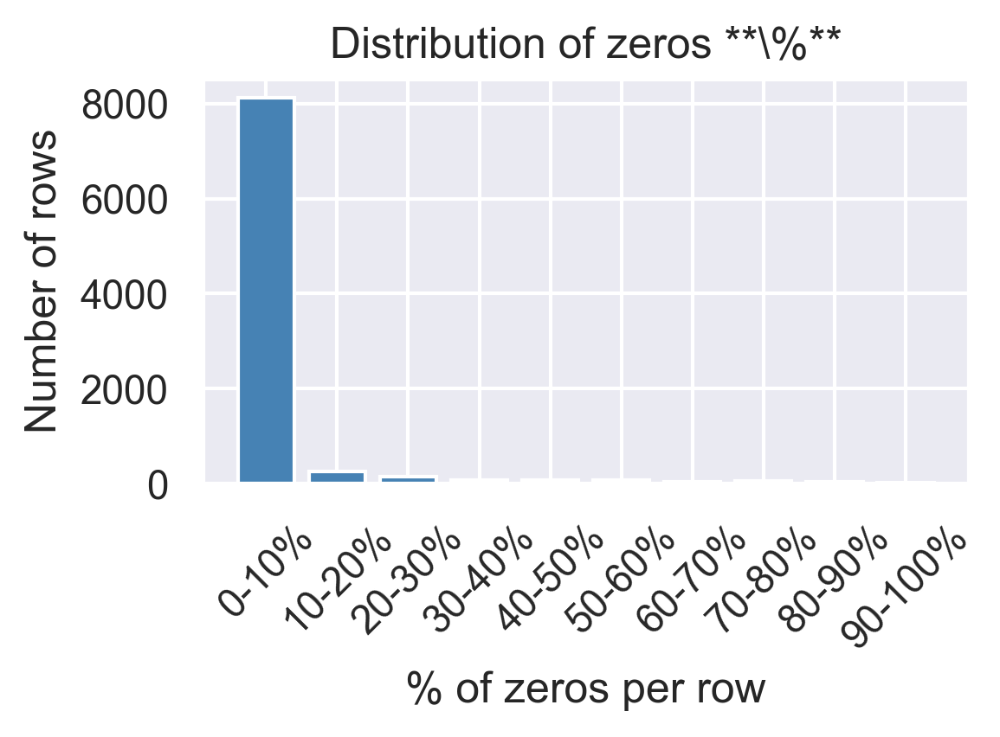

,Protein.Group,Protein.Ids,Protein.Names,Genes,First.Protein.Description,Intensity CtrlminusFBS_0m_Rep1,Intensity CtrlplusFBS_0m_Rep1,Intensity CtrlminusFBS_5m_Rep1,Intensity CtrlplusFBS_5m_Rep1,Intensity CtrlminusFBS_10m_Rep1,...,Intensity FGF2minusFBS_30m_Rep3,Intensity FGF2plusFBS_30m_Rep3,Intensity SOSionFGF2minusFBS_5s_Rep3,Intensity SOSionFGF2plusFBS_5s_Rep3,Intensity SOSionFGF2minusFBS_5m_Rep3,Intensity SOSionFGF2plusFBS_5m_Rep3,Intensity SOSionFGF2minusFBS_10m_Rep3,Intensity SOSionFGF2plusFBS_10m_Rep3,Intensity SOSionFGF2minusFBS_30m_Rep3,Intensity SOSionFGF2plusFBS_30m_Rep3
0,A0A140LIF8,A0A140LIF8,IRGM2_MOUSE,Irgm2,Immunity-related GTPase family M protein 2,15469.70,13471.20,29186.6,NaN,4899.49,...,42599.8,50850.1,52788.4,42977.3,40780.6,40959.0,35145.1,44003.8,44791.2,48684.6
1,A0A140LIF8;Q9DCE9,A0A140LIF8;Q9DCE9,IRGM2_MOUSE;IRGM3_MOUSE,Igtp;Irgm2,Immunity-related GTPase family M protein 2,3037.01,4554.94,NaN,NaN,4429.79,...,11120.0,22654.2,11162.5,27007.7,22207.1,19044.1,21120.4,20599.4,18377.9,21655.3
2,A0A338P6K9,A0A338P6K9,QSER1_MOUSE,Qser1,Glutamine and serine-rich protein 1,22797.00,25539.00,24294.3,27563.6,15980.90,...,12638.0,16580.3,19561.5,20141.0,22638.7,18428.4,18385.1,23909.7,18563.2,16106.3
3,A0A7N9VSG0,A0A7N9VSG0,AFG2B_MOUSE,Afg2b,ATPase family gene 2 protein homolog B,19514.00,19958.50,17549.0,13512.2,18144.80,...,28468.7,31929.7,29482.4,30544.5,20508.5,29714.3,24010.8,23402.6,34742.9,23090.3
4,A1A5B6,A1A5B6,TBC25_MOUSE,Tbc1d25,TBC1 domain family member 25,49883.30,23072.80,21314.6,38515.8,51085.80,...,58335.7,57309.4,48845.8,60830.7,58654.6,57844.5,46896.4,32551.2,57398.4,55153.9


In [30]:

# Import the libraries required for data handling and visualization.
import pandas as pd
import matplotlib.pyplot as plt


# Summarize the distribution of zero values across rows in the dataset.
approx_counts = summarize_zeros(new_dfnp)

# Preview the dataset.
new_dfnp.head()


In [31]:
# Record the number of rows before filtering.
before_count = len(new_dfnp)

# Remove rows containing contaminant entries identified by 'IPI:CON_'.
new_dfnp = new_dfnp[~new_dfnp['Protein.Group'].str.contains('IPI:CON_', na=False)]

# Record the number of rows after filtering.
after_count = len(new_dfnp)

# Report the filtering summary.
print(f"Number of rows before filtering: {before_count}")
print(f"Number of rows after filtering: {after_count}")
print(f"Number of rows removed: {before_count - after_count}")

# Save the filtered dataset before log2 transformation.
new_dfnp.to_csv(
    r'Normal_Proteome/output_files/01_NormalProteome_result.pg_matrix_Clean.tsv',
    sep='\t',
    decimal='.',
    index=False
)

# Identify numeric columns containing intensity values.
numeric_cols = new_dfnp.select_dtypes(include=[np.number]).columns

# Replace zero values with NaN in numeric columns to avoid negative infinity
# during the log2 transformation.
new_dfnp[numeric_cols] = new_dfnp[numeric_cols].replace(0, np.nan)

# Apply the log2 transformation to numeric columns.
new_dfnp[numeric_cols] = np.log2(new_dfnp[numeric_cols])

# Save the filtered dataset after log2 transformation.
new_dfnp.to_csv(
    r'Normal_Proteome/output_files/01_NormalProteome_result.pg_matrix_CleanLog2.tsv',
    sep='\t',
    decimal='.',
    index=False
)

Number of rows before filtering: 8919
Number of rows after filtering: 8786
Number of rows removed: 133


#### 2.3 Histogram and Boxplot of the Data

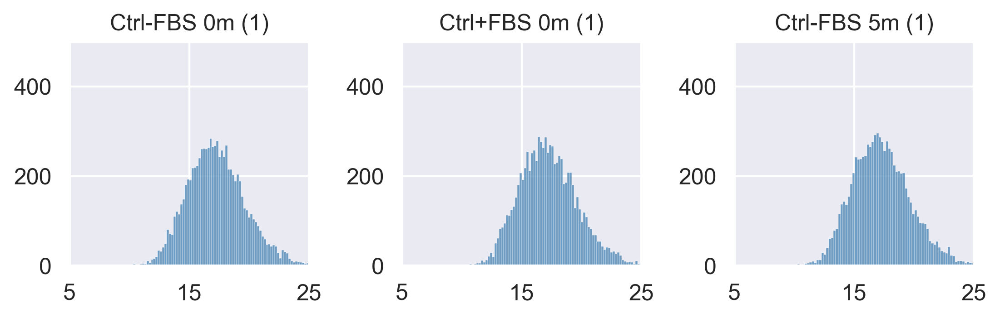

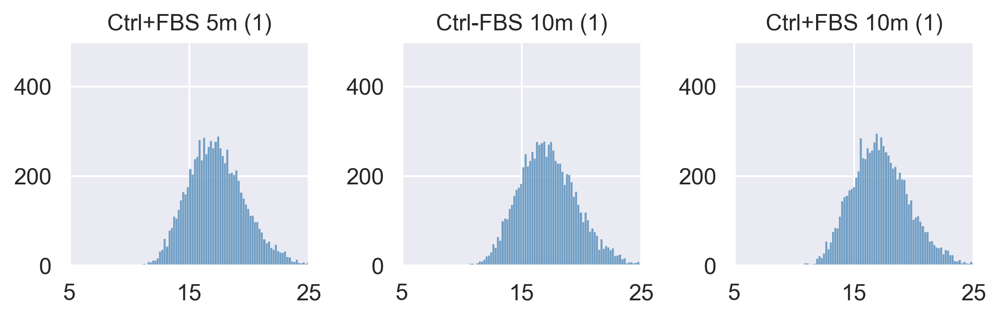

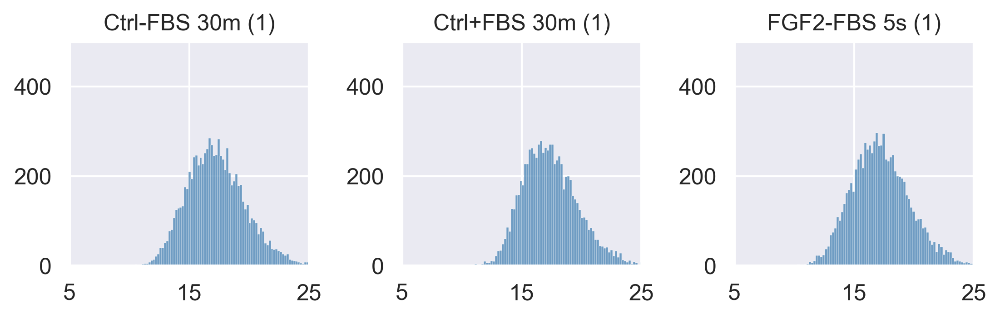

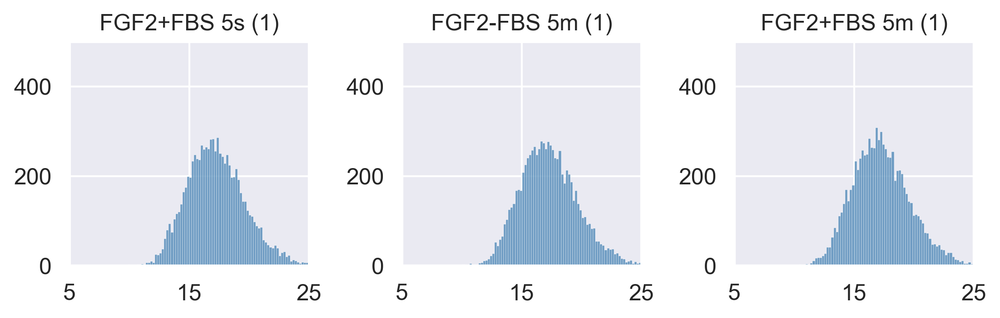

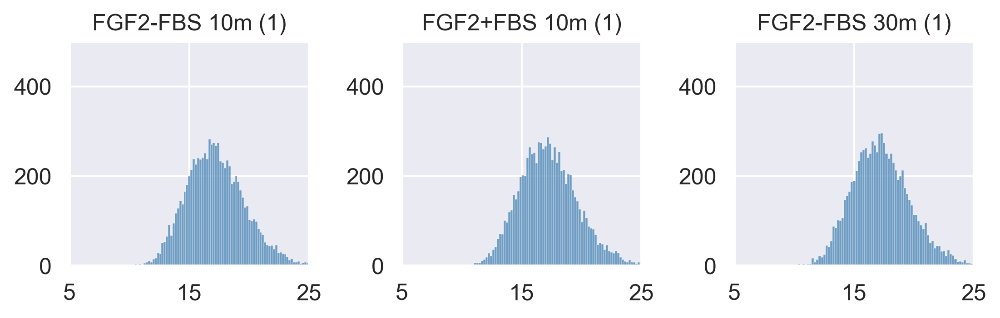

...

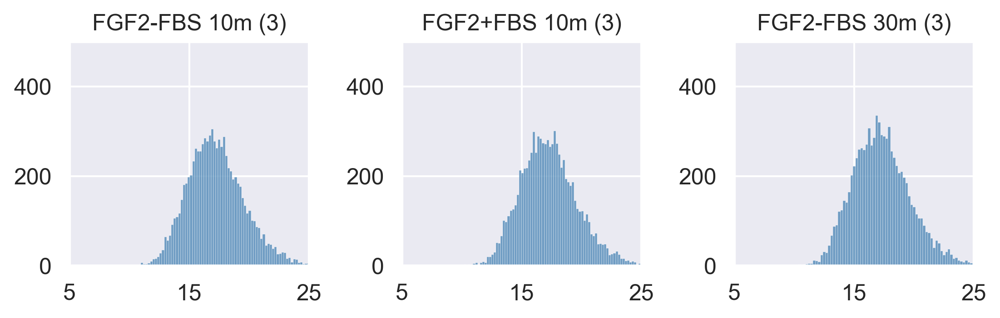

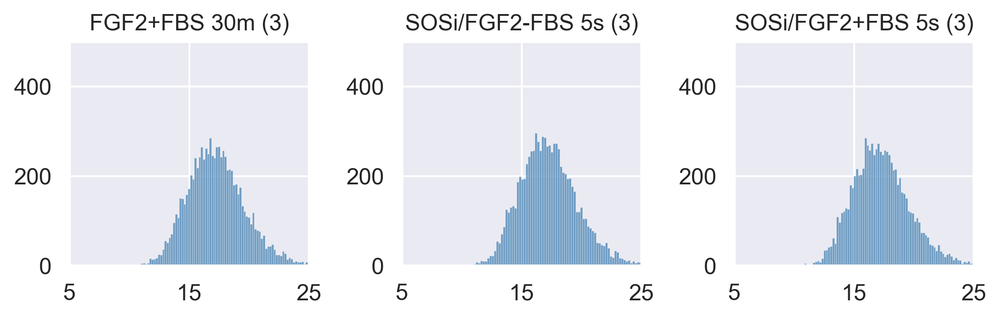

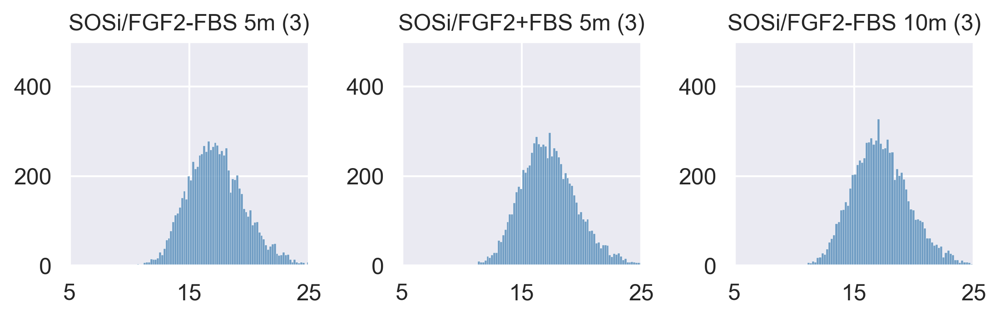

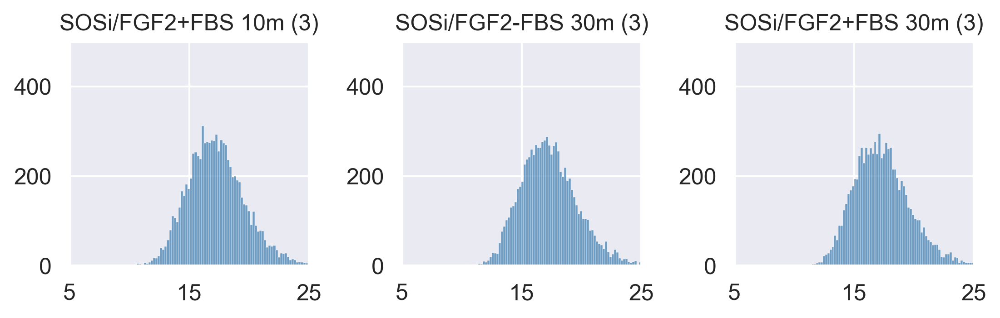

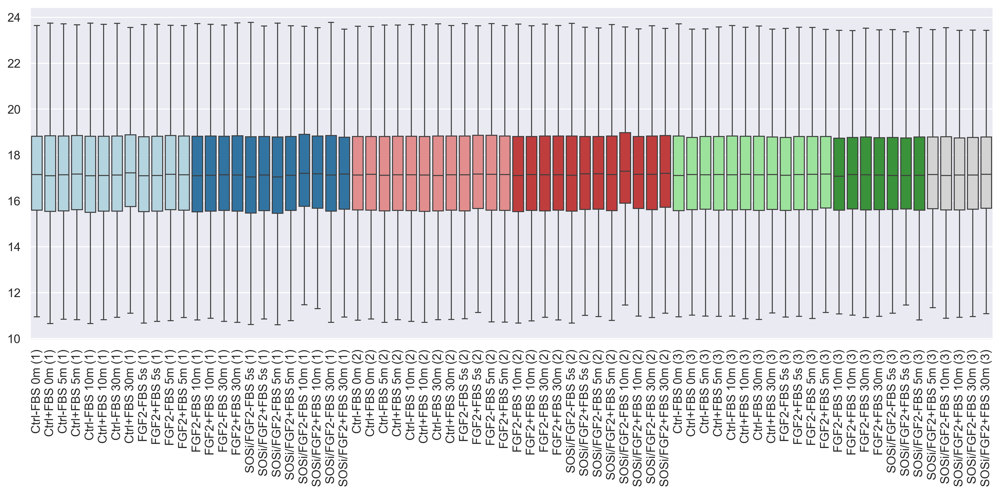

In [32]:
# Generate individual histograms for the numeric columns.
plot_histograms(
    df=new_dfnp[numeric_cols],
    individual=True,
    grouped=False,
    include_zeros=True,
    rename_dict=sampleName_Dict_np,
    xlim=[5, 25],
    ylim=[0, 500],
    xticksDisplayed=[5, 15, 25],
    yticksDisplayed=None,
    xlabel=None,
    ylabel=None,
    title=None,
    title_size=12,
    xtick_labelsize=12,  # Font size of x-axis tick labels.
    ytick_labelsize=12,  # Font size of y-axis tick labels.
    xlabel_size=12,      # Font size of the x-axis label.
    ylabel_size=12       # Font size of the y-axis label.
)

# Generate boxplots for the numeric columns.
plot_boxplot(
    df=new_dfnp[numeric_cols],
    title=None,
    rename_dict=sampleName_Dict_np,
    block_size=12,
    title_size=14,       # Font size of the main title.
    xtick_labelsize=12,  # Font size of x-axis tick labels.
    ytick_labelsize=12,  # Font size of y-axis tick labels.
    xlabel=None,         # Optional x-axis label.
    ylabel=None,         # Optional y-axis label.
    xlabel_size=12,      # Font size of the x-axis label.
    ylabel_size=12       # Font size of the y-axis label.
)

#### 2.4 Replacing Missing inputs with BPCA

##### 2.4.1 Visualizing the Actual Missing Pattern

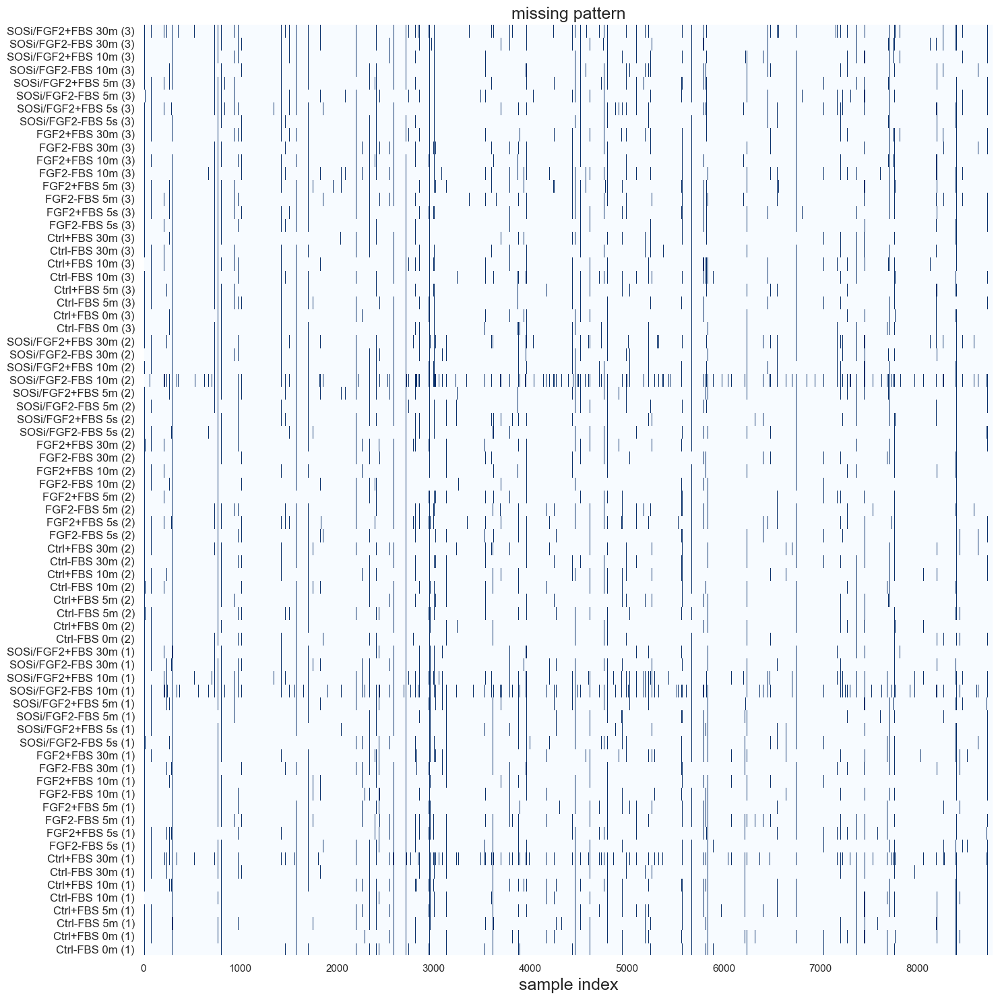

In [33]:
# NOTE:
# The BPCA imputation implementation used in this workflow is based on the
# Python adaptation by Kitamoto et al. (2023), described in the main README.md.
# The original implementation is not included in this repository.
# Please refer to the README for instructions on obtaining and configuring
# the required modules before running this section.

sys.path.append(r"outer_functions/bpca_impute")
sys.path.append(r"outer_functions/bpca_impute_util")

# Import the BPCA imputation modules.
import bpca_impute
import bpca_impute_util

# Rename sample columns for visualization purposes only.
df_renamed = new_dfnp[numeric_cols].rename(columns=sampleName_Dict_np)

# Visualize the binary missing-data pattern.
_, _ = bpca_impute_util.show_missing_pattern_binary(
    df_renamed,
    figsize=(15, 15)
)

##### 2.4.2 Applying BPCA

In [34]:
# Separate numeric and non-numeric columns.
numeric_cols = new_dfnp.select_dtypes(include=[np.number])
text_cols = new_dfnp.select_dtypes(exclude=[np.number])

# Convert the numeric data to a matrix with features as rows and samples as columns.
data_matrix = numeric_cols.to_numpy().T

# Impute missing values using the BPCA-ARD method.
# Note: This method is implemented in an external module that must be obtained
# separately from its original source.
imputed_matrix, param = bpca_impute.impute_bpca_ard(
    data_matrix,
    n_PCs=5,       # Number of latent dimensions.
    eps=1e-4,      # Convergence tolerance for the algorithm.
    a_min=1e-5,    # Minimum threshold for latent-dimension relevance.
    itr_max=200,   # Maximum number of iterations.
    err_L_th=1e-5, # Convergence threshold for the log-likelihood.
    err_x_th=1e-5, # Convergence threshold for missing-value estimates.
    verbose=True
)

# Convert the imputed matrix back to a DataFrame, with samples as columns
# and features as rows.
df_bpca_imputed_np = pd.DataFrame(
    imputed_matrix.T,
    columns=numeric_cols.columns,
    index=numeric_cols.index
)

# Reattach the non-numeric columns while preserving the original row order.
df_bpca_imputed_np_final = pd.concat(
    [text_cols, df_bpca_imputed_np],
    axis=1
)

#samples=8786, obs.dim=72, initial latent dim=5
  20: err_L=0.001368, err_x=0.002432
  40: err_L=0.000217, err_x=0.001034
  60: err_L=0.000091, err_x=0.000676
  80: err_L=0.000048, err_x=0.000490
 100: err_L=0.000028, err_x=0.000376
 120: err_L=0.000017, err_x=0.000299
 140: err_L=0.000012, err_x=0.000244
 160: err_L=0.000008, err_x=0.000203
 180: err_L=0.000006, err_x=0.000172
 200: err_L=0.000004, err_x=0.000148
Finished ARD_BPCA:itr=200, err_L=4.221422906382586e-06, err_x=0.00014802461391959793


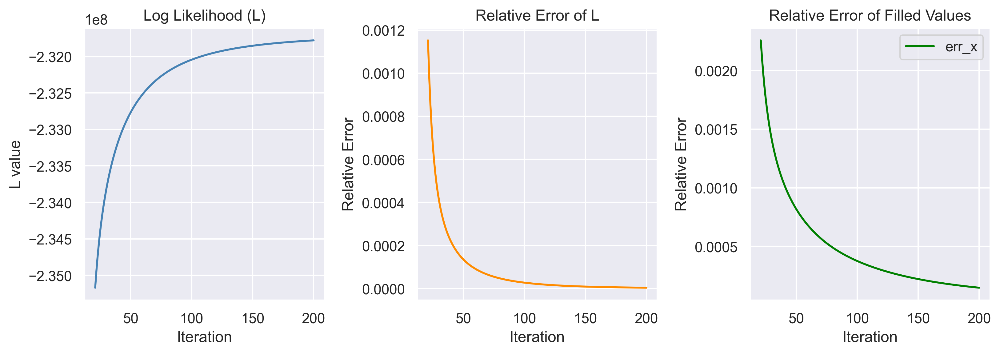

In [35]:
# Extract parameters safely
W = param.get('W')
Z = param.get('Z')
Adiag = param.get('Adiag')
mu = param.get('mu')
err_x = param.get('err_x')
err_W = param.get('err_W', None)  # None if not present
err_L = param.get('err_L', None)
loglik = param.get('loglik', None)

# Create iteration sequence
itr_sequence = np.arange(1, len(err_x)+1)
itr0 = 20  # skip first few iterations for clarity

# Plot all together
fig, ax = plt.subplots(1, 3, figsize=(11,4), dpi=300, sharex=False)

# 1) Log-likelihood
if loglik is not None:
    ax[0].plot(itr_sequence[itr0:], loglik[itr0:], color='steelblue')
    ax[0].set_title('Log Likelihood (L)')
    ax[0].set_xlabel('Iteration')
    ax[0].set_ylabel('L value')

# 2) Relative error of L
if err_L is not None:
    ax[1].plot(itr_sequence[itr0:], err_L[itr0:], color='darkorange')
    ax[1].set_title('Relative Error of L')
    ax[1].set_xlabel('Iteration')
    ax[1].set_ylabel('Relative Error')

# 3) Relative error of filled values (err_x) and optionally err_W
ax[2].plot(itr_sequence[itr0:], err_x[itr0:], label='err_x', color='green')
if err_W is not None:
    ax[2].plot(itr_sequence[itr0:], err_W[itr0:], label='err_W', color='red')
ax[2].set_title('Relative Error of Filled Values')
ax[2].set_xlabel('Iteration')
ax[2].set_ylabel('Relative Error')
ax[2].legend()

fig.tight_layout()
plt.show()

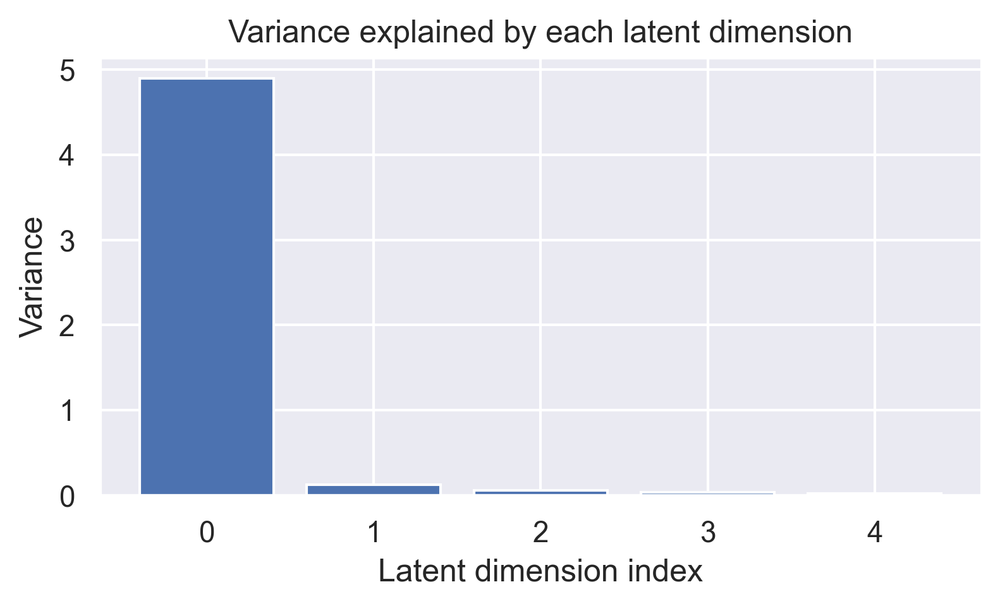

In [36]:
# Plot the variance associated with each latent dimension.
plt.figure(figsize=(6, 3), dpi=300)
plt.bar(np.arange(len(Adiag)), Adiag)
plt.xlabel("Latent dimension index")
plt.ylabel("Variance")
plt.title("Variance explained by each latent dimension")
plt.show()

##### 2.4.3 To show that there is no missing inputs anymore

Total number of missing values after imputation: 0
Any missing values remaining: False


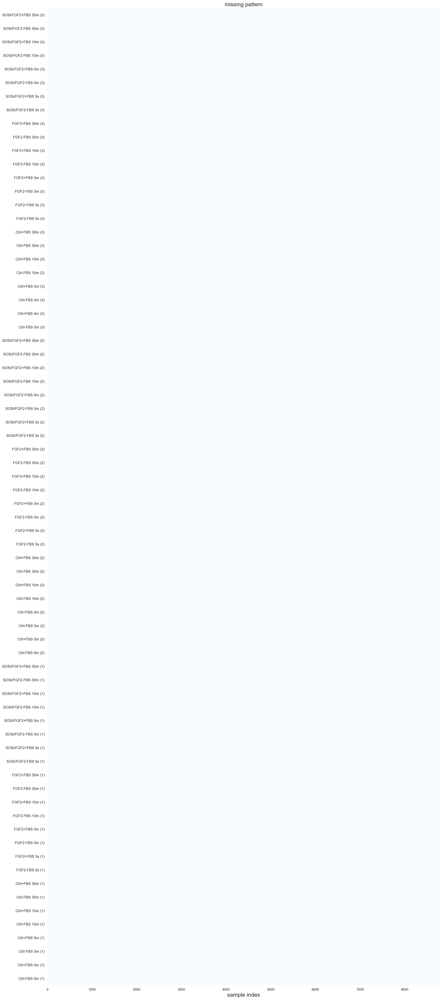

In [37]:
# Rename sample columns for visualization.
df_imputed_renamed = df_bpca_imputed_np.rename(columns=sampleName_Dict_np)

# Visualize the missing-data pattern after imputation.
_, _ = bpca_impute_util.show_missing_pattern_binary(
    df_imputed_renamed,
    figsize=(20, 45)
)

# Check whether any missing values remain in the imputed dataset.
missing_count = df_bpca_imputed_np.isna().sum().sum()
print(f"Total number of missing values after imputation: {missing_count}")
print(f"Any missing values remaining: {df_bpca_imputed_np.isna().values.any()}")

In [38]:
from sklearn.preprocessing import StandardScaler

# Separate numeric and non-numeric columns.
numeric_cols = df_bpca_imputed_np_final.select_dtypes(include='number').columns
non_numeric_cols = df_bpca_imputed_np_final.select_dtypes(exclude='number').columns

# Center the numeric columns by subtracting their means without scaling their variances.
scaler = StandardScaler(with_mean=True, with_std=False)
scaled_numeric = pd.DataFrame(
    scaler.fit_transform(df_bpca_imputed_np_final[numeric_cols]),
    index=df_bpca_imputed_np_final.index,
    columns=numeric_cols
)

# Recombine the centered numeric columns with the non-numeric columns.
df_centered_np = pd.concat(
    [df_bpca_imputed_np_final[non_numeric_cols], scaled_numeric],
    axis=1
)

# Restore the original column order.
df_centered_np = df_centered_np[df_bpca_imputed_np_final.columns]

# Preview the centered dataset.
df_centered_np.head()

,Protein.Group,Protein.Ids,Protein.Names,Genes,First.Protein.Description,Intensity CtrlminusFBS_0m_Rep1,Intensity CtrlplusFBS_0m_Rep1,Intensity CtrlminusFBS_5m_Rep1,Intensity CtrlplusFBS_5m_Rep1,Intensity CtrlminusFBS_10m_Rep1,...,Intensity FGF2minusFBS_30m_Rep3,Intensity FGF2plusFBS_30m_Rep3,Intensity SOSionFGF2minusFBS_5s_Rep3,Intensity SOSionFGF2plusFBS_5s_Rep3,Intensity SOSionFGF2minusFBS_5m_Rep3,Intensity SOSionFGF2plusFBS_5m_Rep3,Intensity SOSionFGF2minusFBS_10m_Rep3,Intensity SOSionFGF2plusFBS_10m_Rep3,Intensity SOSionFGF2minusFBS_30m_Rep3,Intensity SOSionFGF2plusFBS_30m_Rep3
0,A0A140LIF8,A0A140LIF8,IRGM2_MOUSE,Irgm2,Immunity-related GTPase family M protein 2,-3.275641,-3.424838,-2.342758,-3.633573,-4.853599,...,-1.799413,-1.525332,-1.504562,-1.753123,-1.829886,-1.862482,-2.073835,-1.746646,-1.712551,-1.562426
1,A0A140LIF8;Q9DCE9,A0A140LIF8;Q9DCE9,IRGM2_MOUSE;IRGM3_MOUSE,Igtp;Irgm2,Immunity-related GTPase family M protein 2,-5.624363,-4.989212,-4.552770,-4.876558,-4.998993,...,-3.737103,-2.691804,-3.746123,-2.423327,-2.706748,-2.967318,-2.808522,-2.841672,-2.997794,-2.731171
2,A0A338P6K9,A0A338P6K9,QSER1_MOUSE,Qser1,Glutamine and serine-rich protein 1,-2.716243,-2.502014,-2.607446,-2.405760,-3.147954,...,-3.552492,-3.142112,-2.936766,-2.846562,-2.678978,-3.014732,-3.008622,-2.626678,-2.983320,-3.158266
3,A0A7N9VSG0,A0A7N9VSG0,AFG2B_MOUSE,Afg2b,ATPase family gene 2 protein homolog B,-2.940577,-2.857713,-3.076675,-3.434261,-2.964747,...,-2.380883,-2.196683,-2.344929,-2.245785,-2.821547,-2.325505,-2.623475,-2.657605,-2.079048,-2.638604
4,A1A5B6,A1A5B6,TBC25_MOUSE,Tbc1d25,TBC1 domain family member 25,-1.586530,-2.648523,-2.796222,-1.923074,-1.471380,...,-1.345881,-1.352811,-1.616548,-1.251898,-1.305525,-1.364483,-1.657681,-2.181563,-1.354755,-1.382428


## Step 3: Saving the Data

In [39]:
# Save the BPCA-imputed dataset.
df_bpca_imputed_np_final.to_csv(
    r'Normal_Proteome/output_files/02_NormalProteome_result.pg_matrix_BPCA.tsv',
    sep='\t',
    decimal='.',
    index=False
)

# Save the BPCA-imputed and mean-centered dataset.
df_centered_np.to_csv(
    r'Normal_Proteome/output_files/03_NormalProteome_result.pg_matrix_BPCA_Centered.tsv',
    sep='\t',
    decimal='.',
    index=False
)

# Rename sample columns for downstream analyses and visualization,
# then save the dataset with cleaned sample names.
df_centered_np_clearName = df_centered_np.rename(columns=sampleName_Dict_np)

df_centered_np_clearName.to_csv(
    r'Normal_Proteome/output_files/03_NormalProteome_result.pg_matrix_BPCA_Centered_DownstreamReady_CleanNames.tsv',
    sep='\t',
    index=False
)